Team 6 code submission -
Lincon Chopra,
Christopher Chan,
Rojina Adhikari,
Nino Aliashvili

#DATA PULL AND CLEANSING


In [ ]:
import datetime
import os
import random
import shutil
import time
from pprint import pprint

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydot
import requests
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import Image
from sklearn import metrics
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_graphviz, plot_tree



Our Data Pull is in chunks so please give it up to 30 minutes to pull the data into a cache file and let the file run. Please do not interrupt the cell run.

In [ ]:
# Cache file saved to disk
cache_filename = "nyc_311_cached.csv"

if os.path.exists(cache_filename):
    print(f"Using existing cache file: {cache_filename}")
else:
    # Pull 50k rows at a time
    limit = 50000
    offset = 0
    total_records = 0

    while True:
        print(f"Fetching chunk | Offset: {offset} | Total saved: {total_records}")

        query = f"""
        SELECT    unique_key, created_date, closed_date, agency,
        agency_name, complaint_type, descriptor, status,
        resolution_description, police_precinct, borough
        WHERE created_date >= '2026-01-01T00:00:00'
          AND created_date < '2026-04-30T00:00:00'
        LIMIT {limit}
        OFFSET {offset}
        """

        url = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"
        response = requests.get(url, params={"$query": query})

        if response.status_code != 200:
            print("Error:", response.status_code)
            print(response.text)
            break

        data = response.json()

        # Stop when no more records
        if len(data) == 0:
            print("No more data to fetch.")
            break

        # Load only this chunk into RAM
        chunk_df = pd.DataFrame(data)

        # Append this chunk to disk cache file
        chunk_df.to_csv(
            cache_filename,
            mode="a",
            index=False,
            header=not os.path.exists(cache_filename)
        )

        total_records += len(chunk_df)
        print(f"Saved chunk: {len(chunk_df)} rows")

        # If fewer than limit rows returned, final chunk reached
        if len(chunk_df) < limit:
            break

        offset += limit
        time.sleep(0.3)

    print(f"Finished. Total records saved to disk: {total_records}")
    print(f"Cache file created: {cache_filename}")

Fetching chunk | Offset: 0 | Total saved: 0
Saved chunk: 50000 rows
Fetching chunk | Offset: 50000 | Total saved: 50000
Saved chunk: 50000 rows
Fetching chunk | Offset: 100000 | Total saved: 100000
Saved chunk: 50000 rows
Fetching chunk | Offset: 150000 | Total saved: 150000
Saved chunk: 50000 rows
Fetching chunk | Offset: 200000 | Total saved: 200000
Saved chunk: 50000 rows
Fetching chunk | Offset: 250000 | Total saved: 250000
Saved chunk: 50000 rows
Fetching chunk | Offset: 300000 | Total saved: 300000
Saved chunk: 50000 rows
Fetching chunk | Offset: 350000 | Total saved: 350000
Saved chunk: 50000 rows
Fetching chunk | Offset: 400000 | Total saved: 400000
Saved chunk: 50000 rows
Fetching chunk | Offset: 450000 | Total saved: 450000
Saved chunk: 50000 rows
Fetching chunk | Offset: 500000 | Total saved: 500000
Saved chunk: 50000 rows
Fetching chunk | Offset: 550000 | Total saved: 550000
Saved chunk: 50000 rows
Fetching chunk | Offset: 600000 | Total saved: 600000
Saved chunk: 50000 row

In [ ]:
# Load the dataset from disk

cache_filename = "nyc_311_cached.csv"
columns_to_load = [
    "unique_key", "created_date", "closed_date", "agency",
    "agency_name", "complaint_type", "descriptor", "status",
    "resolution_description", "police_precinct", "borough"
]

print("Loading data into memory (this may take a moment)...")

df = pd.read_csv(cache_filename, usecols=columns_to_load, low_memory=False)

# Recalculate resolution days
print("Converting dates...")
df['created_date'] = pd.to_datetime(df['created_date'], errors='coerce', format='ISO8601')
df['closed_date'] = pd.to_datetime(df['closed_date'], errors='coerce', format='ISO8601')

# Calculate resolution days only for rows where both dates are valid
df['resolution_days'] = (df['closed_date'] - df['created_date']).dt.total_seconds() / 86400

print(f"Data loaded. Total records in memory: {len(df)}")
display(df.head())

Loading data into memory (this may take a moment)...
Converting dates...
Data loaded. Total records in memory: 700000


,unique_key,created_date,closed_date,agency,agency_name,complaint_type,descriptor,status,resolution_description,police_precinct,borough,resolution_days
0,67352906,2026-01-01 00:00:00,2026-01-01 00:36:45,NYPD,New York City Police Department,Noise - Commercial,Loud Music/Party,Closed,The New York City Police Department responded ...,Precinct 1,MANHATTAN,0.025521
1,67352467,2026-01-01 00:00:03,2026-01-02 11:52:28,DSNY,Department of Sanitation,Illegal Dumping,Removal Request,Closed,The Department of Sanitation cleaned the locat...,Precinct 111,QUEENS,1.494734
2,67345709,2026-01-01 00:00:10,2026-01-01 00:54:40,NYPD,New York City Police Department,Illegal Fireworks,NaN,Closed,The New York City Police Department responded ...,Precinct 112,QUEENS,0.037847
3,67361228,2026-01-01 00:00:25,2026-01-01 19:25:09,HPD,Department of Housing Preservation and Develop...,HEAT/HOT WATER,ENTIRE BUILDING,Closed,The Department of Housing Preservation and Dev...,Precinct 30,MANHATTAN,0.808843
4,67360282,2026-01-01 00:00:30,2026-01-03 16:58:00,HPD,Department of Housing Preservation and Develop...,HEAT/HOT WATER,ENTIRE BUILDING,Closed,HPD responded to a complaint of no heat or hot...,Precinct 70,BROOKLYN,2.706597


In [ ]:
pprint(df.columns.tolist())

['unique_key',
 'created_date',
 'closed_date',
 'agency',
 'agency_name',
 'complaint_type',
 'descriptor',
 'status',
 'resolution_description',
 'police_precinct',
 'borough',
 'resolution_days']


In [ ]:
df.isnull().sum()

,0
unique_key,0
created_date,0
closed_date,29768
agency,0
agency_name,0
complaint_type,0
descriptor,6439
status,0
resolution_description,8857
police_precinct,0


In [ ]:
# Ensure columns are datetime objects before converting to just dates
df['created_date'] = pd.to_datetime(df['created_date']).dt.date
df['closed_date'] = pd.to_datetime(df['closed_date']).dt.date

# We identify string columns and apply lower()
for col in df.select_dtypes(include=['object']):
    df[col] = df[col].astype(str).str.lower()

df.head(10)

,unique_key,created_date,closed_date,agency,agency_name,complaint_type,descriptor,status,resolution_description,police_precinct,borough,resolution_days
0,67352906,2026-01-01,2026-01-01,nypd,new york city police department,noise - commercial,loud music/party,closed,the new york city police department responded ...,precinct 1,manhattan,0.025521
1,67352467,2026-01-01,2026-01-02,dsny,department of sanitation,illegal dumping,removal request,closed,the department of sanitation cleaned the locat...,precinct 111,queens,1.494734
2,67345709,2026-01-01,2026-01-01,nypd,new york city police department,illegal fireworks,nan,closed,the new york city police department responded ...,precinct 112,queens,0.037847
3,67361228,2026-01-01,2026-01-01,hpd,department of housing preservation and develop...,heat/hot water,entire building,closed,the department of housing preservation and dev...,precinct 30,manhattan,0.808843
4,67360282,2026-01-01,2026-01-03,hpd,department of housing preservation and develop...,heat/hot water,entire building,closed,hpd responded to a complaint of no heat or hot...,precinct 70,brooklyn,2.706597
5,67345829,2026-01-01,2026-01-01,nypd,new york city police department,noise - residential,loud music/party,closed,the new york city police department responded ...,precinct 30,manhattan,0.031609
6,67346787,2026-01-01,2026-01-01,nypd,new york city police department,illegal parking,posted parking sign violation,closed,the new york city police department responded ...,precinct 90,brooklyn,0.006748
7,67350259,2026-01-01,2026-01-01,nypd,new york city police department,illegal parking,blocked hydrant,closed,the new york city police department responded ...,precinct 62,brooklyn,0.055336
8,67350508,2026-01-01,2026-01-01,nypd,new york city police department,illegal fireworks,nan,closed,the new york city police department responded ...,precinct 114,queens,0.014896
9,67359299,2026-01-01,2026-01-03,hpd,department of housing preservation and develop...,heat/hot water,entire building,closed,this complaint is a duplicate of a building-wi...,precinct 120,staten island,2.738333


In [ ]:
# Sort the dataset by created_date in descending order
final_dataset = df.sort_values(by='created_date', ascending=False)

final_dataset.head(10)

,unique_key,created_date,closed_date,agency,agency_name,complaint_type,descriptor,status,resolution_description,police_precinct,borough,resolution_days
699999,68180196,2026-03-02,2026-03-03,dep,department of environmental protection,air quality,"air: odor/fumes, vehicle idling (ad3)",closed,the department of environmental protection wil...,precinct 10,manhattan,1.078472
694896,68176532,2026-03-02,2026-03-03,hpd,department of housing preservation and develop...,heat/hot water,entire building,closed,hpd responded to a complaint of no heat or hot...,precinct 79,brooklyn,1.470012
694884,68178031,2026-03-02,2026-03-03,hpd,department of housing preservation and develop...,heat/hot water,entire building,closed,the department of housing preservation and dev...,precinct 41,bronx,1.078634
694885,68181395,2026-03-02,2026-03-04,dpr,department of parks and recreation,maintenance or facility,garbage or litter,closed,nyc parks has completed the requested work ord...,precinct 48,bronx,2.238461
694886,68186487,2026-03-02,2026-03-02,dot,department of transportation,street condition,pothole,closed,the department of transportation determined th...,precinct 79,brooklyn,0.000000
694887,68178173,2026-03-02,2026-04-23,hpd,department of housing preservation and develop...,general,signage missing,closed,hpd conducted an inspection of this complaint....,precinct 20,manhattan,51.713056
694888,68181213,2026-03-02,nat,dot,department of transportation,street condition,pothole,pending,the department of transportation referred this...,precinct 114,queens,NaN
694889,68175977,2026-03-02,2026-03-02,nypd,new york city police department,illegal parking,posted parking sign violation,closed,the new york city police department responded ...,precinct 30,manhattan,0.056157
694890,68176363,2026-03-02,nat,hpd,department of housing preservation and develop...,flooring/stairs,floor,open,the following complaint conditions are still o...,precinct 34,manhattan,NaN
694891,68183786,2026-03-02,2026-03-04,hpd,department of housing preservation and develop...,heat/hot water,apartment only,closed,hpd responded to a complaint of no heat or hot...,precinct 49,bronx,2.213681


In [ ]:
# Check current date range in the final dataset
print(f"Records in dataset: {len(final_dataset)}")
print(f"Earliest date: {final_dataset['created_date'].min()}")
print(f"Latest date: {final_dataset['created_date'].max()}")

Records in dataset: 700000
Earliest date: 2026-01-01
Latest date: 2026-03-02


# Exploratory Data Analysis (EDA)

In [ ]:
df = final_dataset.copy()

In [ ]:
# Convert to datetime
df['created_date'] = pd.to_datetime(df['created_date'])
df['closed_date'] = pd.to_datetime(df['closed_date'])

# Target variable
df['closed_within_7_days'] = (df['resolution_days'] <= 7).astype(int)

# Time features
df['hour'] = df['created_date'].dt.hour
df['day_of_week'] = df['created_date'].dt.dayofweek
df['month'] = df['created_date'].dt.month

In [ ]:
# Separate cases into resolved and unresolved for further analysis and modeling.
closed_cases_mask = df['status'].eq('closed') & df['resolution_days'].notna()
closed_cases = df.loc[closed_cases_mask].copy()

unresolved_statuses = ['open', 'in progress', 'assigned', 'pending', 'started', 'unspecified']
unresolved_cases = df[df['status'].isin(unresolved_statuses)].copy()

#1 Distribution of Resolution Time

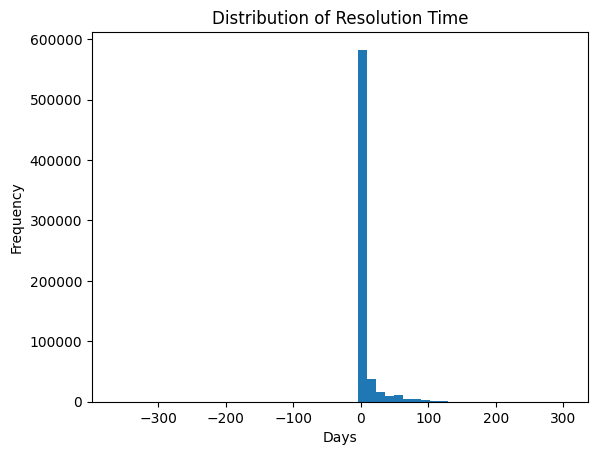

In [ ]:
plt.figure()
plt.hist(df['resolution_days'], bins=50)
plt.title("Distribution of Resolution Time")
plt.xlabel("Days")
plt.ylabel("Frequency")
plt.show()

Figure 1 shows the distribution of resolution time for service requests. Most requests are resolved quickly, as seen by the high concentration near zero, while a small number take much longer, creating a long tail. This indicates that although most cases are handled efficiently, some experience significant delays.

# 2 Target Variable Distribution

(array([0, 1]), [Text(0, 0, '1'), Text(1, 0, '0')])

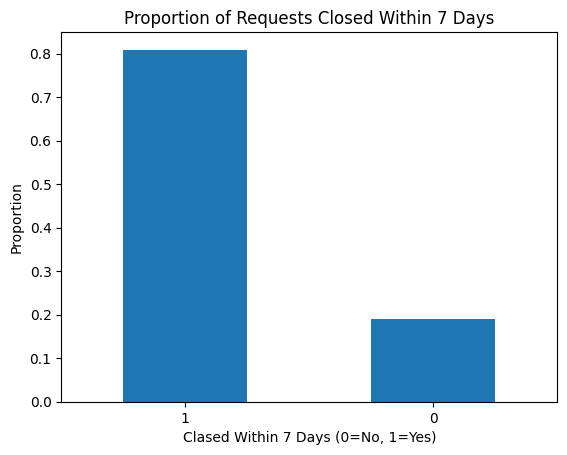

In [ ]:
df['closed_within_7_days'].value_counts(normalize=True).plot(kind='bar')
plt.title("Proportion of Requests Closed Within 7 Days")
plt.xlabel("Clased Within 7 Days (0=No, 1=Yes)")
plt.ylabel("Proportion")
plt.xticks(rotation=0)

Figure 2 shows the proportion of requests resolved within 7 days versus those that are not. The majority of requests are completed within 7 days, indicating a strong class imbalance. This is important for modeling, as it may affect prediction performance and requires careful evaluation.

#3 Closure Rate by Borough

Proportion of Requests Closed Within 7 Days by Borough:
borough
manhattan        77.11
bronx            78.34
brooklyn         80.96
queens           84.71
staten island    88.72
Name: closed_within_7_days, dtype: float64


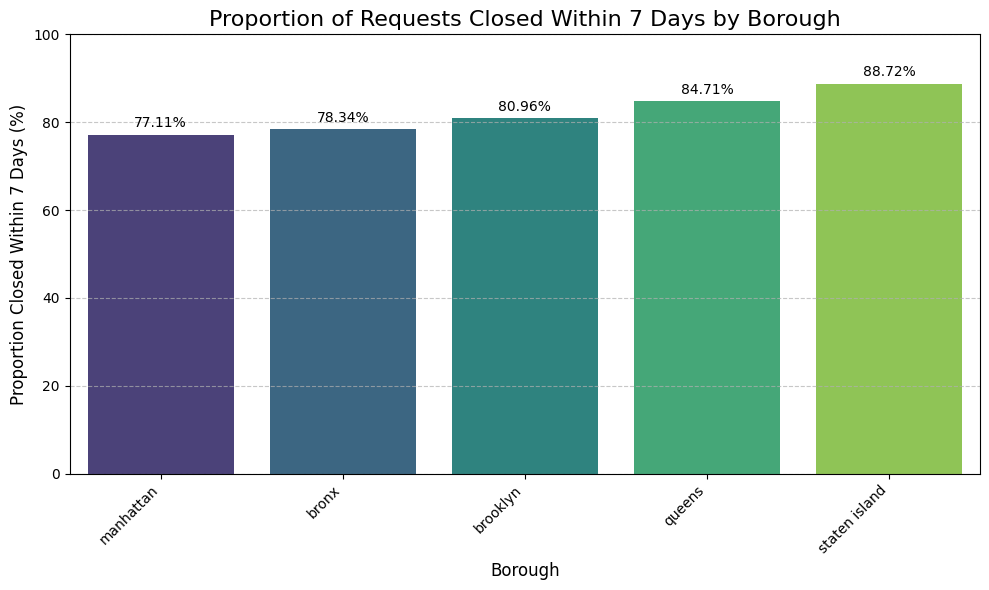

In [ ]:
# Define a list of valid borough names
valid_boroughs = ['manhattan', 'bronx', 'brooklyn', 'staten island', 'queens']

# Filter the DataFrame to include only valid borough names
filtered_df = df[df['borough'].isin(valid_boroughs)].copy()

borough_closure_rates = (
    filtered_df.groupby('borough')['closed_within_7_days']
    .mean()
    .sort_values()
)

print("Proportion of Requests Closed Within 7 Days by Borough:")
print((borough_closure_rates * 100).round(2))

plt.figure(figsize=(10, 6))
sns.barplot(
    x=borough_closure_rates.index,
    y=borough_closure_rates.values * 100,
    hue=borough_closure_rates.index,
    palette='viridis',
    legend=False
)

plt.title("Proportion of Requests Closed Within 7 Days by Borough", fontsize=16)
plt.xlabel("Borough", fontsize=12)
plt.ylabel("Proportion Closed Within 7 Days (%)", fontsize=12)

plt.xticks(rotation=45, ha='right')
plt.ylim(0, 100)

# Add data labels on top of the bars
for index, value in enumerate(borough_closure_rates.values):
    plt.text(index, value * 100 + 1, f'{value*100:.2f}%', ha='center', va='bottom')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Figure 3 shows closure rates across NYC boroughs. The Bronx has the highest rate, while unspecified locations have the lowest, with other boroughs falling in between. This variation suggests that resolution speed differs by location, making borough an important factor in predicting whether requests are resolved within 7 days.

#4 Complaint Type VS Closure Rate

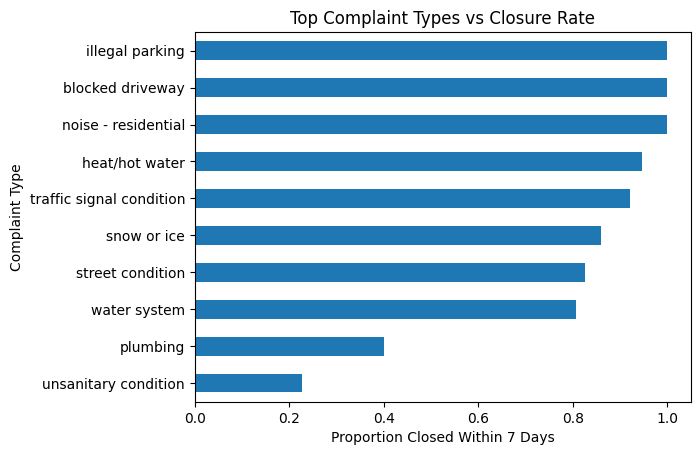

In [ ]:
top_types = df['complaint_type'].value_counts().nlargest(10).index
subset = df[df['complaint_type'].isin(top_types)]

subset.groupby('complaint_type')['closed_within_7_days'].mean().sort_values().plot(kind='barh')

plt.title("Top Complaint Types vs Closure Rate")
plt.xlabel("Proportion Closed Within 7 Days")
plt.ylabel("Complaint Type")
plt.show()

Figure 4 shows closure rates for the most common complaint types. Most complaints, such as noise and illegal parking, are resolved quickly, while others like plumbing and unsanitary conditions have lower closure rates. This suggests that complaint type significantly affects how quickly a request is resolved.

#5 Agency Performance

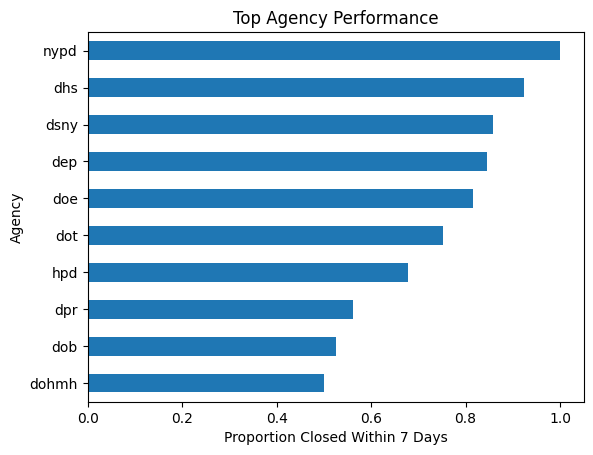

In [ ]:
df.groupby('agency')['closed_within_7_days'] \
  .mean() \
  .sort_values() \
  .tail(10) \
  .plot(kind='barh')

plt.title("Top Agency Performance")
plt.xlabel("Proportion Closed Within 7 Days")
plt.ylabel("Agency")

plt.show()

Figure 5 shows closure rates across agencies, with some agencies like NYPD resolving requests faster than others such as DHS. This variation suggests that agency plays an important role in determining how quickly requests are resolved.

#6 Closure Rate by Day of Week

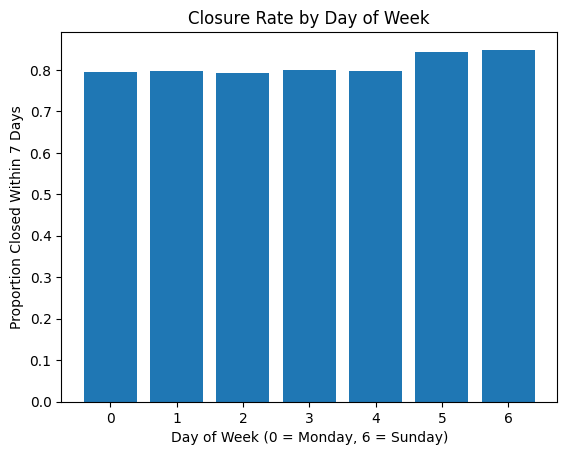

In [ ]:


day_rate = df.groupby('day_of_week')['closed_within_7_days'].mean()

plt.bar(day_rate.index, day_rate.values)

plt.title("Closure Rate by Day of Week")
plt.xlabel("Day of Week (0 = Monday, 6 = Sunday)")
plt.ylabel("Proportion Closed Within 7 Days")

plt.show()

Figure 6 shows how closure rates vary by day of the week. Requests submitted later in the week and on weekends tend to have slightly higher closure rates, while midweek days are slightly lower. This suggests that the day of submission may influence how quickly requests are resolved.

#7 Correlation Heatmap

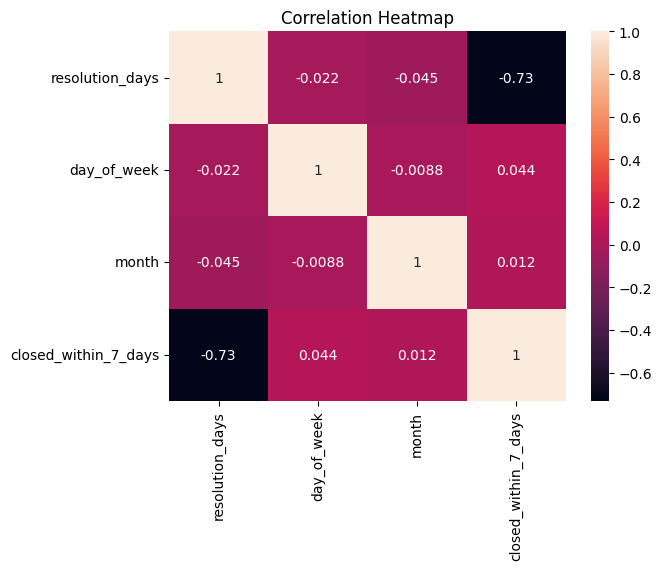

In [ ]:


corr = df[['resolution_days','day_of_week','month','closed_within_7_days']].corr()

sns.heatmap(corr, annot=True)

plt.title("Correlation Heatmap")

plt.show()

Figure 7 shows the correlations between key variables. Resolution time has a strong negative relationship with whether a request is closed within 7 days, while time related features such as hour, day of week, and month show very weak correlations. This suggests that resolution time is the most important factor, while timing variables have limited influence on closure speed.

# 8. Agency Workload vs. Efficiency

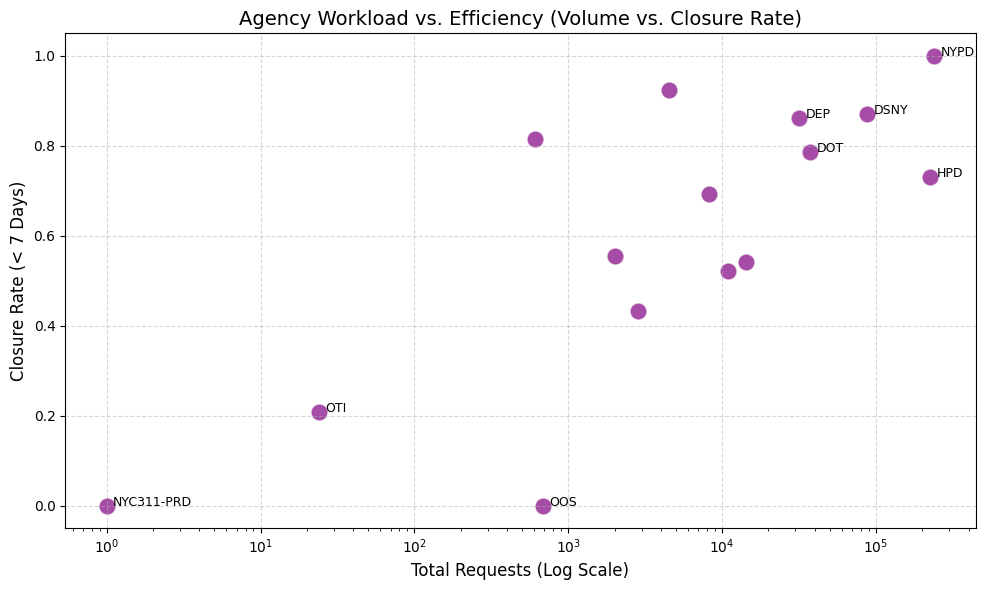

In [ ]:


# Group by agency to get total volume and closure rate
agency_stats = closed_cases.groupby('agency').agg(
    total_requests=('unique_key', 'count'),
    closure_rate=('closed_within_7_days', 'mean')
).reset_index()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=agency_stats, x='total_requests', y='closure_rate', s=150, color='purple', alpha=0.7)

# Annotate the top agencies by volume or poor performance for clarity
for i in range(len(agency_stats)):
    if agency_stats['total_requests'][i] > 20000 or agency_stats['closure_rate'][i] < 0.3:
        plt.text(agency_stats['total_requests'][i] * 1.1,
                 agency_stats['closure_rate'][i],
                 agency_stats['agency'][i].upper(),
                 fontsize=9)

plt.title('Agency Workload vs. Efficiency (Volume vs. Closure Rate)', fontsize=14)
plt.xlabel('Total Requests (Log Scale)', fontsize=12)
plt.ylabel('Closure Rate (< 7 Days)', fontsize=12)
plt.xscale('log')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 9. Resolution Time Distribution by Borough

/tmp/ipykernel_2131/3843814186.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


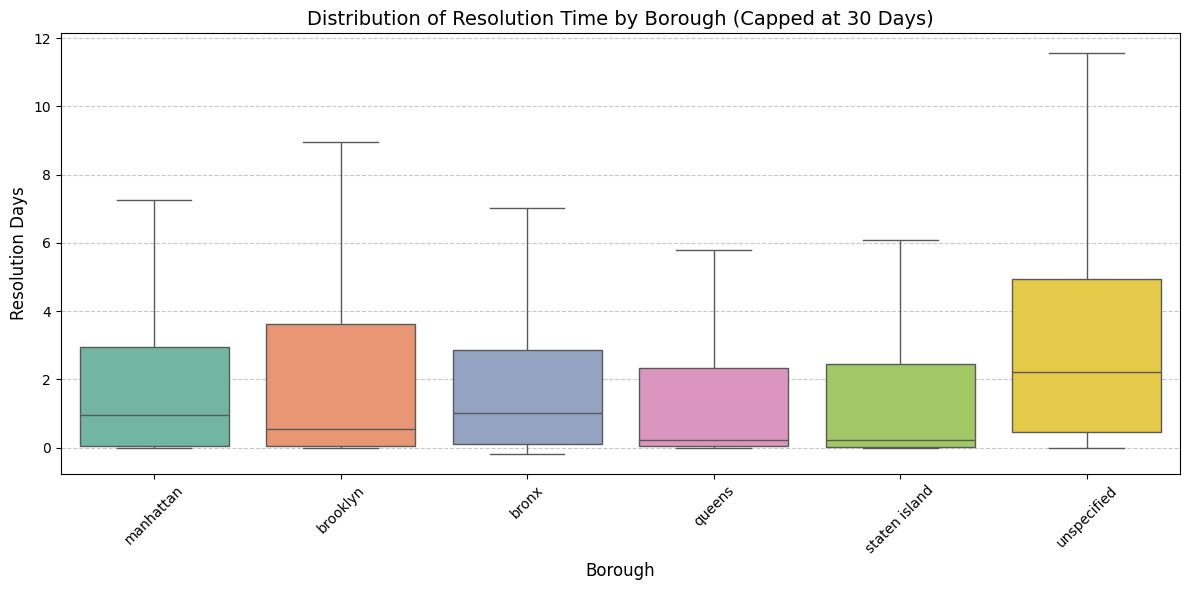

In [ ]:
plt.figure(figsize=(12, 6))

# Filter to <= 30 days to avoid outliers squishing the plot
sns.boxplot(
    data=closed_cases[closed_cases['resolution_days'] <= 30],
    x='borough',
    y='resolution_days',
    palette='Set2',
    showfliers=False
)

plt.title('Distribution of Resolution Time by Borough (Capped at 30 Days)', fontsize=14)
plt.xlabel('Borough', fontsize=12)
plt.ylabel('Resolution Days', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Overall EDA Summary & Key Findings

The exploratory data analysis identified several variables strongly associated with whether a NYC 311 request closed within 7 days. Borough level analysis showed noticeable variation in closure rates, with the Bronx demonstrating one of the highest proportions of requests resolved within the 7 day threshold, while requests with unspecified borough information showed the lowest closure rates. This suggests that geographic location may influence response efficiency and therefore serves as a meaningful predictor variable.

The complaint type distribution was also highly uneven, with a small number of complaint categories accounting for a disproportionately large share of requests. This indicates that certain complaint categories generate substantially higher operational demand, which may increase response times and reduce the likelihood of rapid closure.

Temporal analysis further revealed that request activity fluctuated across different months, days, and hours. Periods with higher request volumes appeared more likely to experience slower resolution patterns, suggesting that workload intensity and timing may affect operational efficiency.

The EDA demonstrated that variables such as borough, complaint type, agency, and request timing show measurable differences in closure outcomes, making them valuable features for predicting whether a request will close within 7 days using classification models such as Logistic Regression and KNN.


# Logistic Regression + inference

In [ ]:
# Prepare data
model_df = final_dataset.copy()
model_df['created_date'] = pd.to_datetime(model_df['created_date'], errors='coerce')
model_df['closed_date'] = pd.to_datetime(model_df['closed_date'], errors='coerce')


In [ ]:
# Create target variable and keep only rows with known outcome
closed_mask = model_df['status'].eq('closed') & model_df['resolution_days'].notna()
closed_cases = model_df.loc[closed_mask].copy()
closed_cases['closed_within_7_days'] = (closed_cases['resolution_days'] <= 7).astype(int)

# Keep rows that still need predictions
unresolved_statuses = ['open', 'in progress', 'assigned', 'pending', 'started', 'unspecified']
unresolved_cases = model_df[model_df['status'].isin(unresolved_statuses)].copy()


In [ ]:
# Create time features
closed_cases['hour'] = closed_cases['created_date'].dt.hour
closed_cases['day_of_week'] = closed_cases['created_date'].dt.dayofweek
closed_cases['month'] = closed_cases['created_date'].dt.month

unresolved_cases['hour'] = unresolved_cases['created_date'].dt.hour
unresolved_cases['day_of_week'] = unresolved_cases['created_date'].dt.dayofweek
unresolved_cases['month'] = unresolved_cases['created_date'].dt.month


In [ ]:
# Select feature columns
feature_cols = [
    'agency',
    'complaint_type',
    'borough',
    'hour',
    'day_of_week',
    'month'
]

closed_cases[feature_cols + ['closed_within_7_days']].head()


,agency,complaint_type,borough,hour,day_of_week,month,closed_within_7_days
699999,dep,air quality,manhattan,0,0,3,1
694896,hpd,heat/hot water,brooklyn,0,0,3,1
694884,hpd,heat/hot water,bronx,0,0,3,1
694885,dpr,maintenance or facility,bronx,0,0,3,1
694886,dot,street condition,brooklyn,0,0,3,1


In [ ]:
# Prepare data set for training
X = closed_cases[feature_cols].copy()
y = closed_cases['closed_within_7_days']
X = pd.get_dummies(X, drop_first=True, sparse=True)


In [ ]:
# Split data into 75% training and 25% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)


In [ ]:
# Train logistic regression model
model = LogisticRegression(max_iter = 200)
model.fit(X_train, y_train)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(


LogisticRegression(max_iter=200)

In [ ]:
print(f"\nclasses: {model.classes_}\n")
print(f"number of features: {model.n_features_in_}\n")
print(f"features: {model.feature_names_in_}\n")
print(f"intercept: {model.intercept_}\n")
print(f"coefficents: {model.coef_}")



classes: [0 1]

number of features: 178

features: ['hour' 'day_of_week' 'month' 'agency_dep' 'agency_dhs' 'agency_dob'
 'agency_doe' 'agency_dohmh' 'agency_dot' 'agency_dpr' 'agency_dsny'
 'agency_hpd' 'agency_nyc311-prd' 'agency_nypd' 'agency_oos' 'agency_oti'
 'agency_tlc' 'complaint_type_abandoned vehicle'
 'complaint_type_ahv inspection unit' 'complaint_type_air quality'
 'complaint_type_animal facility - no permit'
 'complaint_type_animal in a park' 'complaint_type_animal-abuse'
 'complaint_type_appliance' 'complaint_type_asbestos'
 'complaint_type_beach/pool/sauna complaint' 'complaint_type_bench'
 'complaint_type_best/site safety' 'complaint_type_bike rack'
 'complaint_type_bike/roller/skate' 'complaint_type_blocked driveway'
 'complaint_type_boilers' 'complaint_type_bridge condition'
 'complaint_type_broken parking meter'
 'complaint_type_building drinking water tank'
 "complaint_type_building marshal's office" 'complaint_type_building/use'
 'complaint_type_bus stop shelter c

In [ ]:
# Generate predictions against the test set, predicted Y on the test data
predictions = model.predict(X_test)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(


In [ ]:
# Calculate model accuracy
accuracy = model.score(X_test, y_test)
print('accuracy =', round((accuracy * 100), 2), '%')


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(


accuracy = 90.56 %


In [ ]:
# Print classification report
#  Check precision, recall, f1-score
target_names = ['not closed within 7 days', 'closed within 7 days']
print(classification_report(y_test, predictions, target_names=target_names))


                          precision    recall  f1-score   support

not closed within 7 days       0.69      0.71      0.70     25598
    closed within 7 days       0.95      0.94      0.94    140749

                accuracy                           0.91    166347
               macro avg       0.82      0.83      0.82    166347
            weighted avg       0.91      0.91      0.91    166347



In [ ]:
# Print confusion matrix
cnf_matrix = confusion_matrix(y_test, predictions)
cnf_matrix


array([[ 18230,   7368],
       [  8329, 132420]])

In [ ]:
# Display the probability of each class for each data instance
model.predict_proba(X_test)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(


array([[5.64254573e-01, 4.35745427e-01],
       [3.06549193e-03, 9.96934508e-01],
       [9.90406253e-06, 9.99990096e-01],
       ...,
       [2.16383695e-05, 9.99978362e-01],
       [5.61261253e-03, 9.94387387e-01],
       [1.39828829e-01, 8.60171171e-01]])

In [ ]:
# Build a compact final metrics table for the test set
test_probabilities = model.predict_proba(X_test)[:, 1]

model_performance_table = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC'],
    'Test Set Score': [
        accuracy_score(y_test, predictions),
        precision_score(y_test, predictions, zero_division=0),
        recall_score(y_test, predictions, zero_division=0),
        f1_score(y_test, predictions, zero_division=0),
        roc_auc_score(y_test, test_probabilities)
    ]
})

display(model_performance_table.round(4))


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(


,Metric,Test Set Score
0,Accuracy,0.9056
1,Precision,0.9473
2,Recall,0.9408
3,F1 Score,0.9440
4,ROC AUC,0.9473


In [ ]:
# Classification report as a table
classification_table = pd.DataFrame(
    classification_report(
        y_test,
        predictions,
        target_names=target_names,
        output_dict=True,
        zero_division=0
    )
).T

display(classification_table.round(4))


,precision,recall,f1-score,support
not closed within 7 days,0.6864,0.7122,0.6990,25598.0000
closed within 7 days,0.9473,0.9408,0.9440,140749.0000
accuracy,0.9056,0.9056,0.9056,0.9056
macro avg,0.8168,0.8265,0.8215,166347.0000
weighted avg,0.9071,0.9056,0.9063,166347.0000


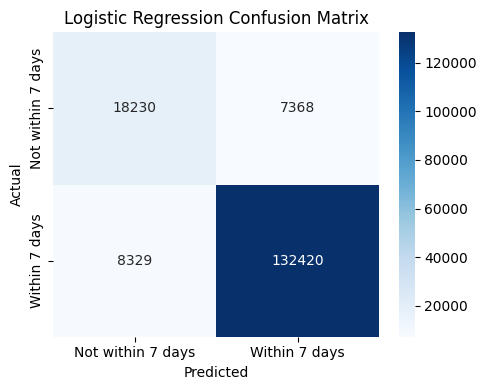

In [ ]:
# Confusion matrix heatmap
cnf_matrix = confusion_matrix(y_test, predictions)
confusion_labels = ['Not within 7 days', 'Within 7 days']

plt.figure(figsize=(5, 4))
sns.heatmap(
    cnf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=confusion_labels,
    yticklabels=confusion_labels
)
plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()


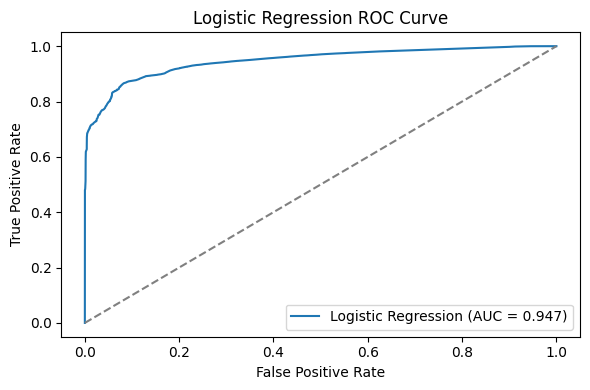

In [ ]:
# ROC curve for logistic regression
fpr, tpr, thresholds = metrics.roc_curve(y_test, test_probabilities)
roc_auc = metrics.auc(fpr, tpr)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.title('Logistic Regression ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


#Inference

In [ ]:
# Prepare an inference dataset focused only on agency and complaint type
inference_df = closed_cases[
    ['closed_within_7_days', 'agency', 'complaint_type']
].dropna().copy()

# Agency indicators
for agency in ['hpd', 'dob', 'dohmh', 'dsny', 'dep', 'dot', 'dpr','nypd']:
    inference_df[f'is_{agency}'] = inference_df['agency'].eq(agency).astype(int)

# Complaint-type indicators
housing_maintenance_types = [
    'unsanitary condition',
    'appliance',
    'door/window',
    'flooring/stairs',
    'general',
    'water leak',
    'paint/plaster',
    'plumbing',
    'electric'
]

inference_df['is_housing_maintenance'] = (
    inference_df['complaint_type'].isin(housing_maintenance_types)
).astype(int)
inference_df['is_heat_hot_water'] = inference_df['complaint_type'].eq('heat/hot water').astype(int)
inference_df['is_snow_or_ice'] = inference_df['complaint_type'].eq('snow or ice').astype(int)
inference_df['is_dirty_condition'] = inference_df['complaint_type'].eq('dirty condition').astype(int)
inference_df['is_street_condition'] = inference_df['complaint_type'].eq('street condition').astype(int)
inference_df['is_water_system'] = inference_df['complaint_type'].eq('water system').astype(int)

# Use a sample
inference_sample_size = min(100000, len(inference_df))

if inference_sample_size < len(inference_df):
    _, inference_sample = train_test_split(
        inference_df,
        test_size=inference_sample_size,
        random_state=42,
        stratify=inference_df['closed_within_7_days']
    )
else:
    inference_sample = inference_df.copy()

print("Inference sample size:", len(inference_sample))
print("Outcome rate in inference sample:")
print(inference_sample['closed_within_7_days'].value_counts(normalize=True).sort_index().round(4))


Inference sample size: 100000
Outcome rate in inference sample:
closed_within_7_days
0    0.1539
1    0.8461
Name: proportion, dtype: float64


In [ ]:
# Fit the logistic regression inference model
inference_formula = (
    "closed_within_7_days ~ "
    "is_hpd + is_nypd + is_dob + is_dohmh + is_dsny + is_dep + is_dot + is_dpr + "
    "is_housing_maintenance + is_heat_hot_water + is_snow_or_ice + "
    "is_dirty_condition + is_street_condition + is_water_system"
)

inference_model = smf.logit(inference_formula, data=inference_sample).fit()

# View model summary
print(inference_model.summary())


Optimization terminated successfully.
         Current function value: 0.232535
         Iterations 14
                            Logit Regression Results                            
Dep. Variable:     closed_within_7_days   No. Observations:               100000
Model:                            Logit   Df Residuals:                    99985
Method:                             MLE   Df Model:                           14
Date:                  Fri, 15 May 2026   Pseudo R-squ.:                  0.4584
Time:                          11:51:19   Log-Likelihood:                -23254.
converged:                         True   LL-Null:                       -42938.
Covariance Type:              nonrobust   LLR p-value:                     0.000
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  0.6140      0.052     11.736      0.000 

In [ ]:
# Convert coefficients to odds ratios for easier interpretation
inference_conf = inference_model.conf_int()

inference_odds_table = pd.DataFrame({
    'Predictor': inference_model.params.index,
    'Coefficient': inference_model.params.values,
    'Odds Ratio': np.exp(inference_model.params.values),
    'CI Lower': np.exp(inference_conf[0].values),
    'CI Upper': np.exp(inference_conf[1].values),
    'P-value': inference_model.pvalues.values
})

inference_odds_table = inference_odds_table[
    inference_odds_table['Predictor'] != 'Intercept'
].copy()

agency_predictors = ['is_hpd', 'is_dob', 'is_dohmh', 'is_dsny', 'is_dep', 'is_dot', 'is_dpr', 'is_nypd']
inference_odds_table['Predictor Type'] = np.where(
    inference_odds_table['Predictor'].isin(agency_predictors),
    'Agency',
    'Complaint Type'
)

inference_odds_table['Association'] = np.where(
    inference_odds_table['Coefficient'] > 0,
    'Higher odds of closing within 7 days',
    'Lower odds of closing within 7 days'
)

display(
    inference_odds_table
    .sort_values(['Predictor Type', 'Odds Ratio'], ascending=[True, False])
    .round(4)
)


,Predictor,Coefficient,Odds Ratio,CI Lower,CI Upper,P-value,Predictor Type,Association
2,is_nypd,9.8743,19424.2157,2728.7638,138267.7968,0.0000,Agency,Higher odds of closing within 7 days
6,is_dep,1.4509,4.2668,3.6400,5.0014,0.0000,Agency,Higher odds of closing within 7 days
5,is_dsny,1.2095,3.3520,2.9148,3.8547,0.0000,Agency,Higher odds of closing within 7 days
7,is_dot,0.4029,1.4962,1.3204,1.6953,0.0000,Agency,Higher odds of closing within 7 days
8,is_dpr,0.3039,1.3552,1.1552,1.5898,0.0002,Agency,Higher odds of closing within 7 days
3,is_dob,-0.4665,0.6272,0.5488,0.7168,0.0000,Agency,Lower odds of closing within 7 days
4,is_dohmh,-0.6128,0.5418,0.4707,0.6237,0.0000,Agency,Lower odds of closing within 7 days
1,is_hpd,-0.8699,0.4190,0.3423,0.5130,0.0000,Agency,Lower odds of closing within 7 days
10,is_heat_hot_water,6.0579,427.4788,314.8100,580.4713,0.0000,Complaint Type,Higher odds of closing within 7 days
13,is_street_condition,1.3893,4.0121,3.3385,4.8215,0.0000,Complaint Type,Higher odds of closing within 7 days


# Logistic Regression Cross Validation

In [ ]:
# Set up cross validation for logistic regression
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_model = LogisticRegression(max_iter=200)

cv_scoring = ['accuracy', 'precision', 'recall', 'f1']
cv_results = cross_validate(
    cv_model,
    X,
    y,
    cv=cv,
    scoring=cv_scoring,
    return_train_score=False
)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklea

In [ ]:
# Display fold by fold cross-validation results
lr_cv_results = ({
    'Model': ['Logistical Regression'],
    'CV Accuracy': [cv_results['test_accuracy'].mean()],
    'CV Precision': [cv_results['test_precision'].mean()],
    'CV Recall': [cv_results['test_recall'].mean()],
    'CV F1-score': [cv_results['test_f1'].mean()]
})
lr_cv_results

{'Model': ['Logistical Regression'],
 'CV Accuracy': [np.float64(0.9052716689627841)],
 'CV Precision': [np.float64(0.9467491359236722)],
 'CV Recall': [np.float64(0.9409691744859279)],
 'CV F1-score': [np.float64(0.9438501733104208)]}

# Model KNN  

In [ ]:
# Timeframe Used
print("Timeframe used:")
print("Start:", closed_cases['created_date'].min())
print("End:", closed_cases['created_date'].max())

Timeframe used:
Start: 2026-01-01 00:00:00
End: 2026-03-02 00:00:00


In [ ]:
# Select feature columns
feature_cols = [
    'agency',
    'complaint_type',
    'borough',
    'hour',
    'day_of_week',
    'month'
]

closed_cases[feature_cols + ['closed_within_7_days']].head()

# Prepare X and y
model_data = closed_cases[feature_cols + ['closed_within_7_days']].dropna().copy()

X = model_data[feature_cols]
y = model_data['closed_within_7_days']

print("Dataset size:", model_data.shape)

Dataset size: (665387, 7)


In [ ]:
# Since KNN is slow on big data, taking sample size to reduce computational time
sample_size = 30000

model_data_knn = model_data.sample(
    n=min(sample_size, len(model_data)),
    random_state=42
)

In [ ]:
# redefine x and y for KNN model
X_knn = model_data_knn[feature_cols]
y_knn = model_data_knn['closed_within_7_days']

# test-train split (75% training and 25% testing)
X_train_knn, X_test_knn, y_train_knn, y_test_knn = train_test_split(
    X_knn,
    y_knn,
    test_size=0.25,
    random_state=42,
    stratify=y_knn
)

In [ ]:
# Preprocess the data (using one-hot encoding and scaling numeric variables using standardization)
categorical_features = ['agency', 'complaint_type', 'borough']
numeric_features = ['hour', 'day_of_week', 'month']

preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ('num', StandardScaler(), numeric_features)
])

In [ ]:
# KNN model using K = 5 (default)

knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier(n_neighbors=5))
])


In [ ]:
# Train Model
knn_pipeline.fit(X_train_knn, y_train_knn)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['agency', 'complaint_type',
                                                   'borough']),
                                                 ('num', StandardScaler(),
                                                  ['hour', 'day_of_week',
                                                   'month'])])),
                ('model', KNeighborsClassifier())])

In [ ]:
# Make Prediction on unseen data
y_pred_knn = knn_pipeline.predict(X_test_knn)

In [ ]:
# Evaluate KNN model
print("KNN Performance")
print("Accuracy:", accuracy_score(y_test_knn, y_pred_knn))
print("Precision:", precision_score(y_test_knn, y_pred_knn))
print("Recall:", recall_score(y_test_knn, y_pred_knn))
print("F1-score:", f1_score(y_test_knn, y_pred_knn))

KNN Performance
Accuracy: 0.8941333333333333
Precision: 0.9341054938174989
Recall: 0.9411764705882353
F1-score: 0.9376276512175963


In [ ]:
# Classification Report
print(classification_report(y_test_knn, y_pred_knn))

              precision    recall  f1-score   support

           0       0.66      0.64      0.65      1159
           1       0.93      0.94      0.94      6341

    accuracy                           0.89      7500
   macro avg       0.80      0.79      0.79      7500
weighted avg       0.89      0.89      0.89      7500



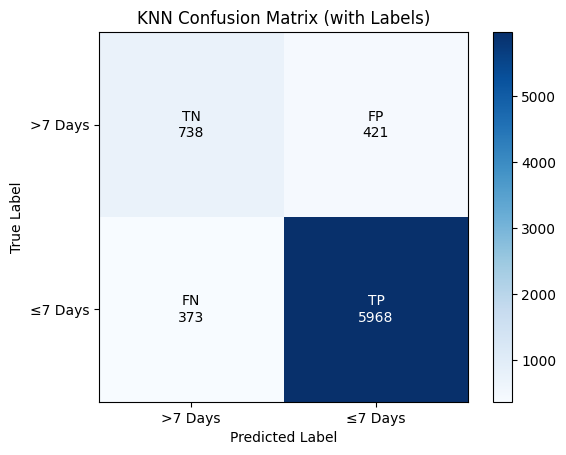

In [ ]:
#KNN confusion Matrix
cm = confusion_matrix(y_test_knn, y_pred_knn)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['>7 Days', '≤7 Days']
)

disp.plot(cmap='Blues', include_values=False)

# Add TP, FP, FN, TN with dynamic color
for i in range(2):
    for j in range(2):
        value = cm[i, j]

        color = 'white' if value > cm.max()/2 else 'black'

        label = ""
        if i == 0 and j == 0:
            label = "TN"
        elif i == 0 and j == 1:
            label = "FP"
        elif i == 1 and j == 0:
            label = "FN"
        elif i == 1 and j == 1:
            label = "TP"

        plt.text(j, i, f"{label}\n{value}",
                 ha='center', va='center',
                 color=color, fontsize=10)

plt.title("KNN Confusion Matrix (with Labels)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

# Model: Decision tree

In [ ]:
# Prepare full dataset
model_data_full = closed_cases[feature_cols + ['closed_within_7_days']].dropna().copy()

# Reset X and y to full data
X = model_data_full[feature_cols]
y = model_data_full['closed_within_7_days']

print("Full dataset size:", model_data_full.shape)

Full dataset size: (665387, 7)


In [ ]:
# Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

In [ ]:
# Build decision tree model
tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=50,
        random_state=42
    ))
])

In [ ]:
# Train model
tree_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['agency', 'complaint_type',
                                                   'borough']),
                                                 ('num', StandardScaler(),
                                                  ['hour', 'day_of_week',
                                                   'month'])])),
                ('model',
                 DecisionTreeClassifier(max_depth=5, min_samples_leaf=50,
                                        random_state=42))])

In [ ]:
# Predict model
y_pred_tree = tree_pipeline.predict(X_test)

# Evaluate Model
print("Decision Tree Performance")
print("Accuracy:", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall:", recall_score(y_test, y_pred_tree))
print("F1-score:", f1_score(y_test, y_pred_tree))

Decision Tree Performance
Accuracy: 0.8941790353898778
Precision: 0.9297929667322807
Recall: 0.9463939353032703
F1-score: 0.9380200062673629


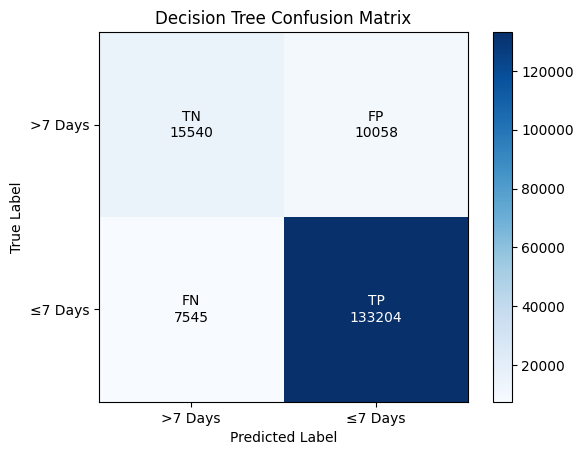

In [ ]:
# Confusion matrix
# Compute confusion matrix
cm_tree = confusion_matrix(y_test, y_pred_tree)

# Display with text labels instead of 0/1
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tree,
    display_labels=['>7 Days', '≤7 Days']
)

# Remove default numbers (to avoid duplication)
disp.plot(cmap='Blues', include_values=False)

# Adding TP, FP, FN, TN with dynamic color
for i in range(2):
    for j in range(2):
        value = cm_tree[i, j]

        # White text for dark cells, black for light
        color = 'white' if value > cm_tree.max()/2 else 'black'

        # Assign labels
        if i == 0 and j == 0:
            label = "TN"
        elif i == 0 and j == 1:
            label = "FP"
        elif i == 1 and j == 0:
            label = "FN"
        else:
            label = "TP"

        plt.text(j, i, f"{label}\n{value}",
                 ha='center', va='center',
                 color=color, fontsize=10)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

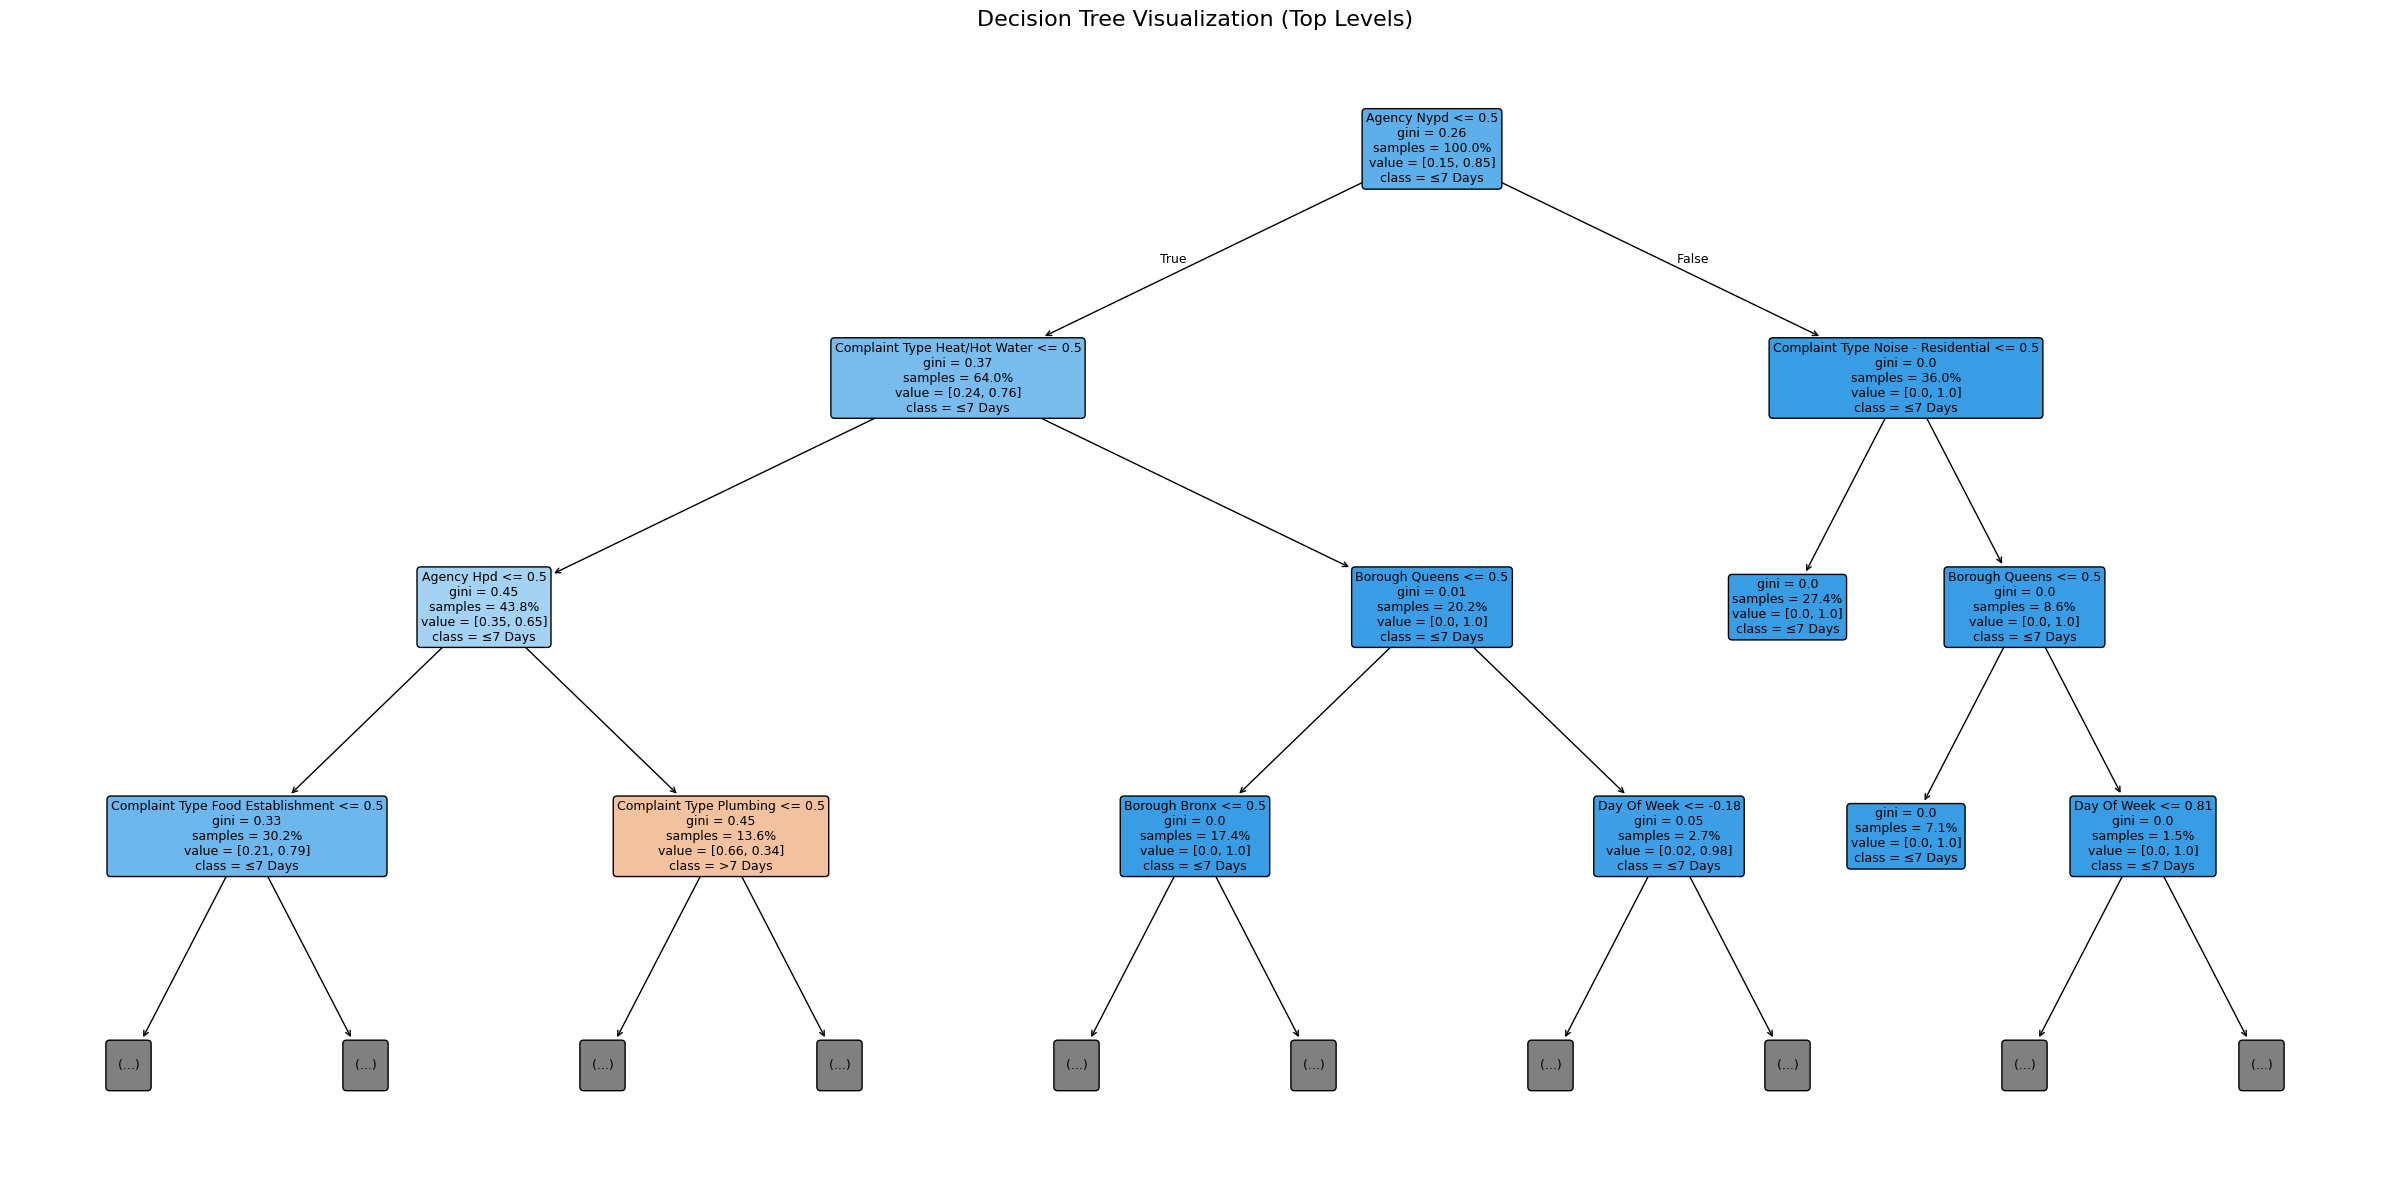

In [ ]:
# Decision tree visualization
# Get feature names
feature_names = tree_pipeline.named_steps['preprocessor'].get_feature_names_out()

# Clean feature names
clean_feature_names = [
    f.replace('cat__', '').replace('num__', '').replace('_', ' ').title()
    for f in feature_names
]

plt.figure(figsize=(24, 12))

plot_tree(
    tree_pipeline.named_steps['model'],
    feature_names=clean_feature_names,
    class_names=['>7 Days', '≤7 Days'],
    filled=True,
    rounded=True,
    proportion=True,
    precision=2,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree Visualization (Top Levels)", fontsize=16)
plt.tight_layout()

plt.show()

In [ ]:
# Create Decision Tree feature importance
feature_importance = tree_pipeline.named_steps['model'].feature_importances_
feature_names = tree_pipeline.named_steps['preprocessor'].get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
}).sort_values(by='Importance', ascending=False)

# Clean feature names
importance_df['Feature'] = (
    importance_df['Feature']
    .str.replace('cat__', '', regex=False)
    .str.replace('num__', '', regex=False)
    .str.replace('_', ' ')
    .str.title()
)

# Display top 10
top_features = importance_df.head(10)
top_features

,Feature,Importance
9,Agency Hpd,0.367355
75,Complaint Type Heat/Hot Water,0.306317
10,Agency Nypd,0.248537
66,Complaint Type Food Establishment,0.033007
3,Agency Dob,0.028662
121,Complaint Type Plumbing,0.008789
58,Complaint Type Electric,0.006804
173,Borough Queens,0.000240
178,Month,0.000219
177,Day Of Week,0.000069


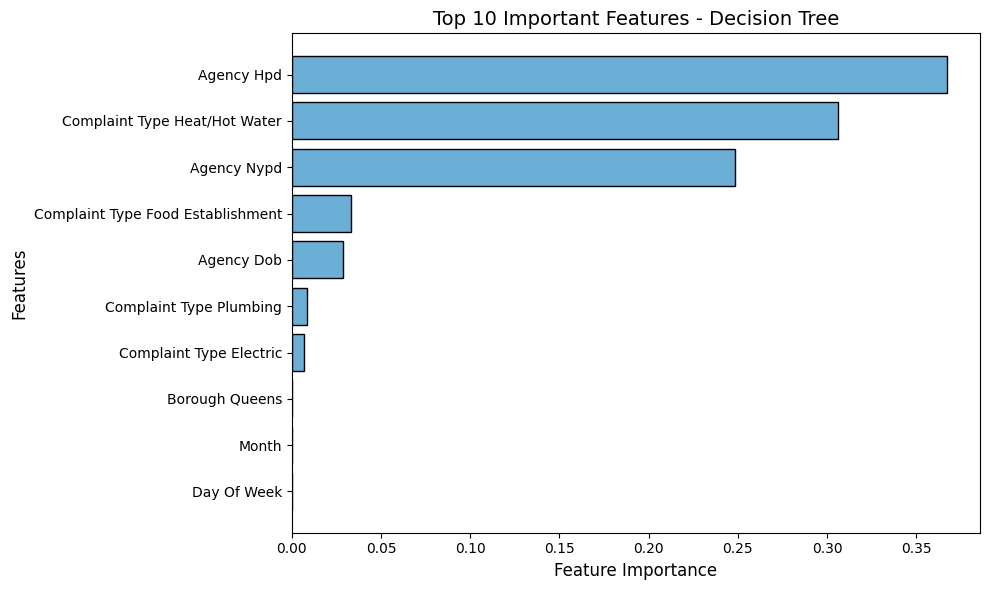

In [ ]:
# Feature Importance plot
plt.figure(figsize=(10, 6))

plt.barh(
    top_features['Feature'],
    top_features['Importance'],
    color='#6BAED6',
    edgecolor='black'
)

plt.xlabel("Feature Importance", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.title("Top 10 Important Features - Decision Tree", fontsize=14)

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

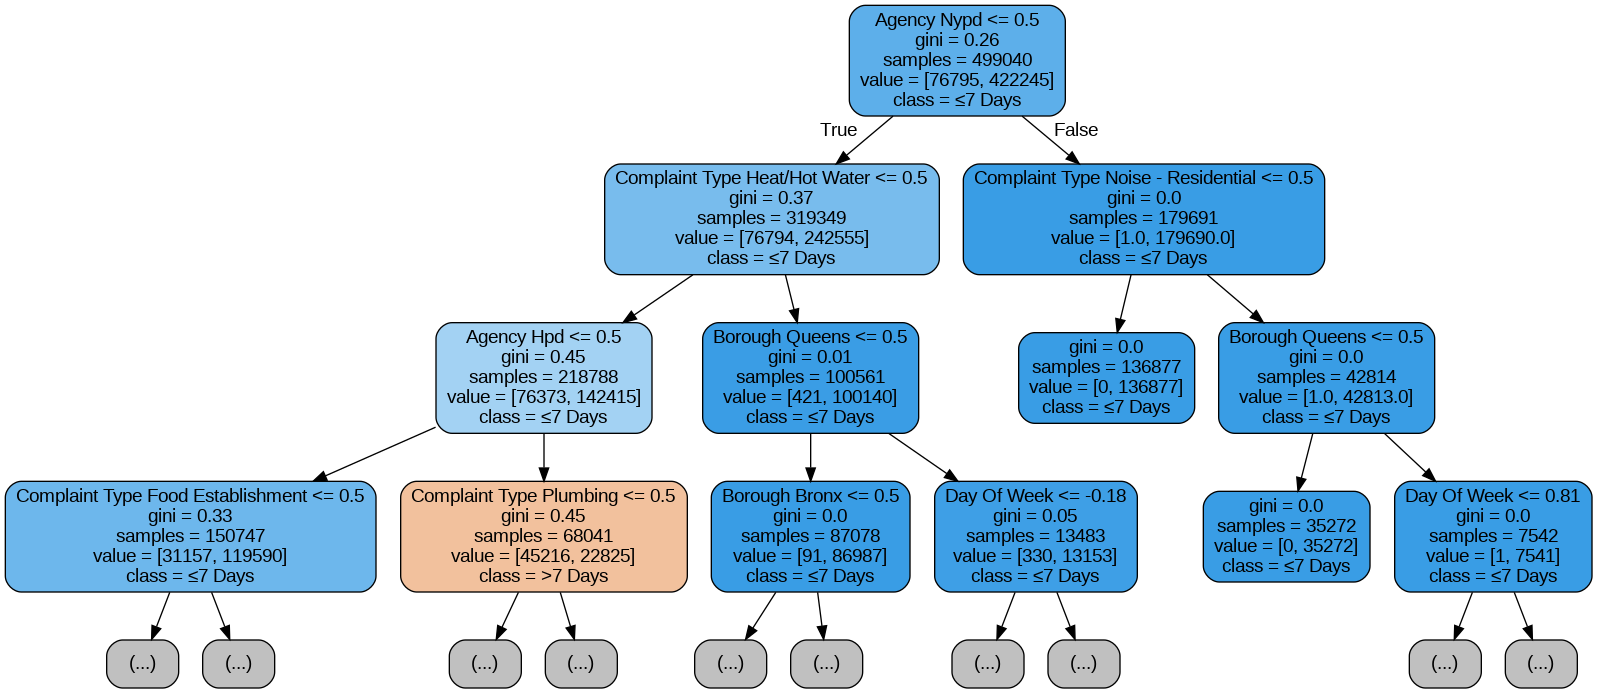

In [ ]:


# Get trained decision tree model
tree_model = tree_pipeline.named_steps['model']

# Get and clean feature names
feature_names = tree_pipeline.named_steps['preprocessor'].get_feature_names_out()

clean_feature_names = [
    f.replace('cat__', '').replace('num__', '').replace('_', ' ').title()
    for f in feature_names
]

# Export decision tree as DOT file
export_graphviz(
    tree_model,
    out_file='decision_tree_small.dot',
    feature_names=clean_feature_names,
    class_names=['>7 Days', '≤7 Days'],
    filled=True,
    rounded=True,
    precision=2,
    max_depth=3
)

# Convert DOT file to PNG
(graph,) = pydot.graph_from_dot_file('decision_tree_small.dot')
graph.write_png('decision_tree_small.png')

# Display PNG
Image(filename='decision_tree_small.png')

# Model: Random Forest

In [ ]:
# Build Random Forest Model
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=50,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
# Train Random Forest Model
rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['agency', 'complaint_type',
                                                   'borough']),
                                                 ('num', StandardScaler(),
                                                  ['hour', 'day_of_week',
                                                   'month'])])),
                ('model',
                 RandomForestClassifier(max_depth=10, min_samples_leaf=50,
                                        n_jobs=-1, random_state=42))])

In [ ]:
# Predict
y_pred_rf = rf_pipeline.predict(X_test)

In [ ]:
# Model Evaluation
print("Random Forest Performance")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1-score:", f1_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Performance
Accuracy: 0.8742508130594481
Precision: 0.8817124836747046
Recall: 0.9832965065471158
F1-score: 0.9297379364087681

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.27      0.40     25598
           1       0.88      0.98      0.93    140749

    accuracy                           0.87    166347
   macro avg       0.82      0.63      0.67    166347
weighted avg       0.86      0.87      0.85    166347



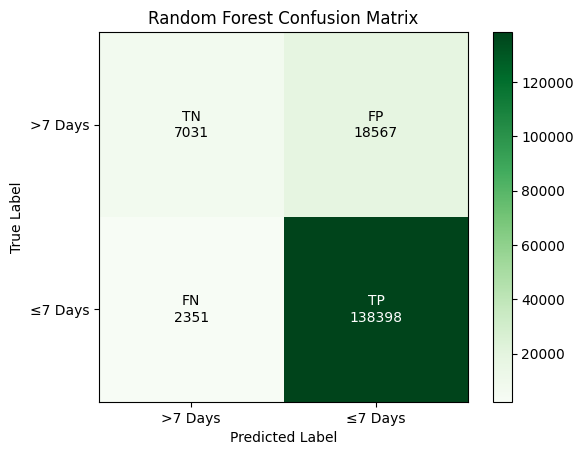

In [ ]:
# Confusion Matrix
# Compute confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Display with meaningful labels
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=['>7 Days', '≤7 Days']
)

# Remove default numbers (avoid duplication)
disp.plot(cmap='Greens', include_values=False)

# Add TN, FP, FN, TP with dynamic color
for i in range(2):
    for j in range(2):
        value = cm_rf[i, j]

        # Dynamic text color for readability
        color = 'white' if value > cm_rf.max()/2 else 'black'

        # Assign labels
        if i == 0 and j == 0:
            label = "TN"
        elif i == 0 and j == 1:
            label = "FP"
        elif i == 1 and j == 0:
            label = "FN"
        else:
            label = "TP"

        plt.text(j, i, f"{label}\n{value}",
                 ha='center', va='center',
                 color=color, fontsize=10)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

In [ ]:
# Feature importance
# Create importance dataframe
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
}).sort_values(by='Importance', ascending=False)

# CLEAN feature names
importance_df['Feature'] = (
    importance_df['Feature']
    .str.replace('cat__', '', regex=False)
    .str.replace('num__', '', regex=False)
    .str.replace('_', ' ')
    .str.title()
)

# View top features
importance_df.head(10)

,Feature,Importance
9,Agency Hpd,0.367355
75,Complaint Type Heat/Hot Water,0.306317
10,Agency Nypd,0.248537
66,Complaint Type Food Establishment,0.033007
3,Agency Dob,0.028662
121,Complaint Type Plumbing,0.008789
58,Complaint Type Electric,0.006804
173,Borough Queens,0.000240
178,Month,0.000219
177,Day Of Week,0.000069


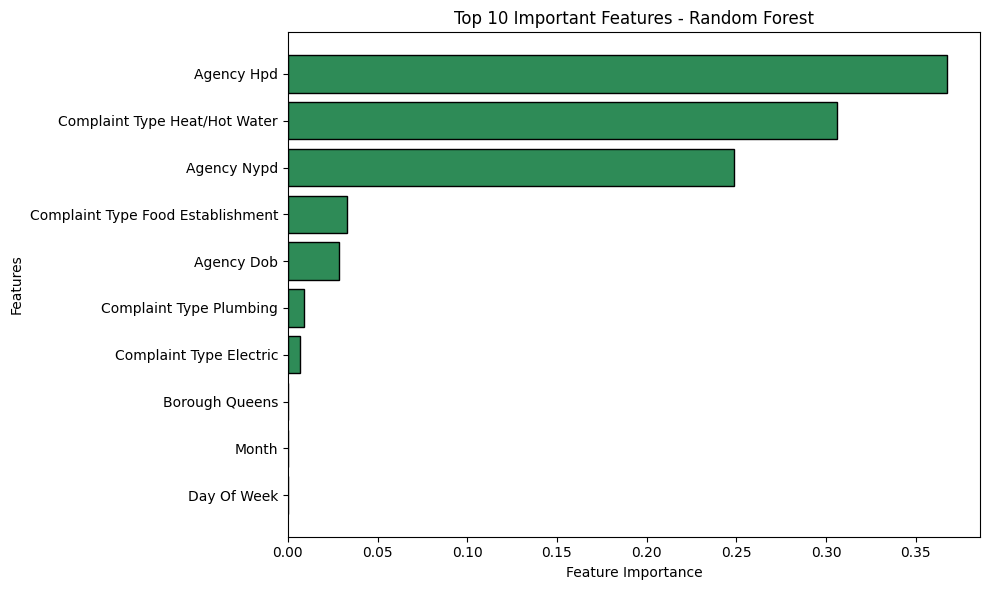

In [ ]:

top_features = importance_df.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features['Feature'],
    top_features['Importance'],
    color= '#2E8B57',
    edgecolor='black'
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Features - Random Forest")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.show()

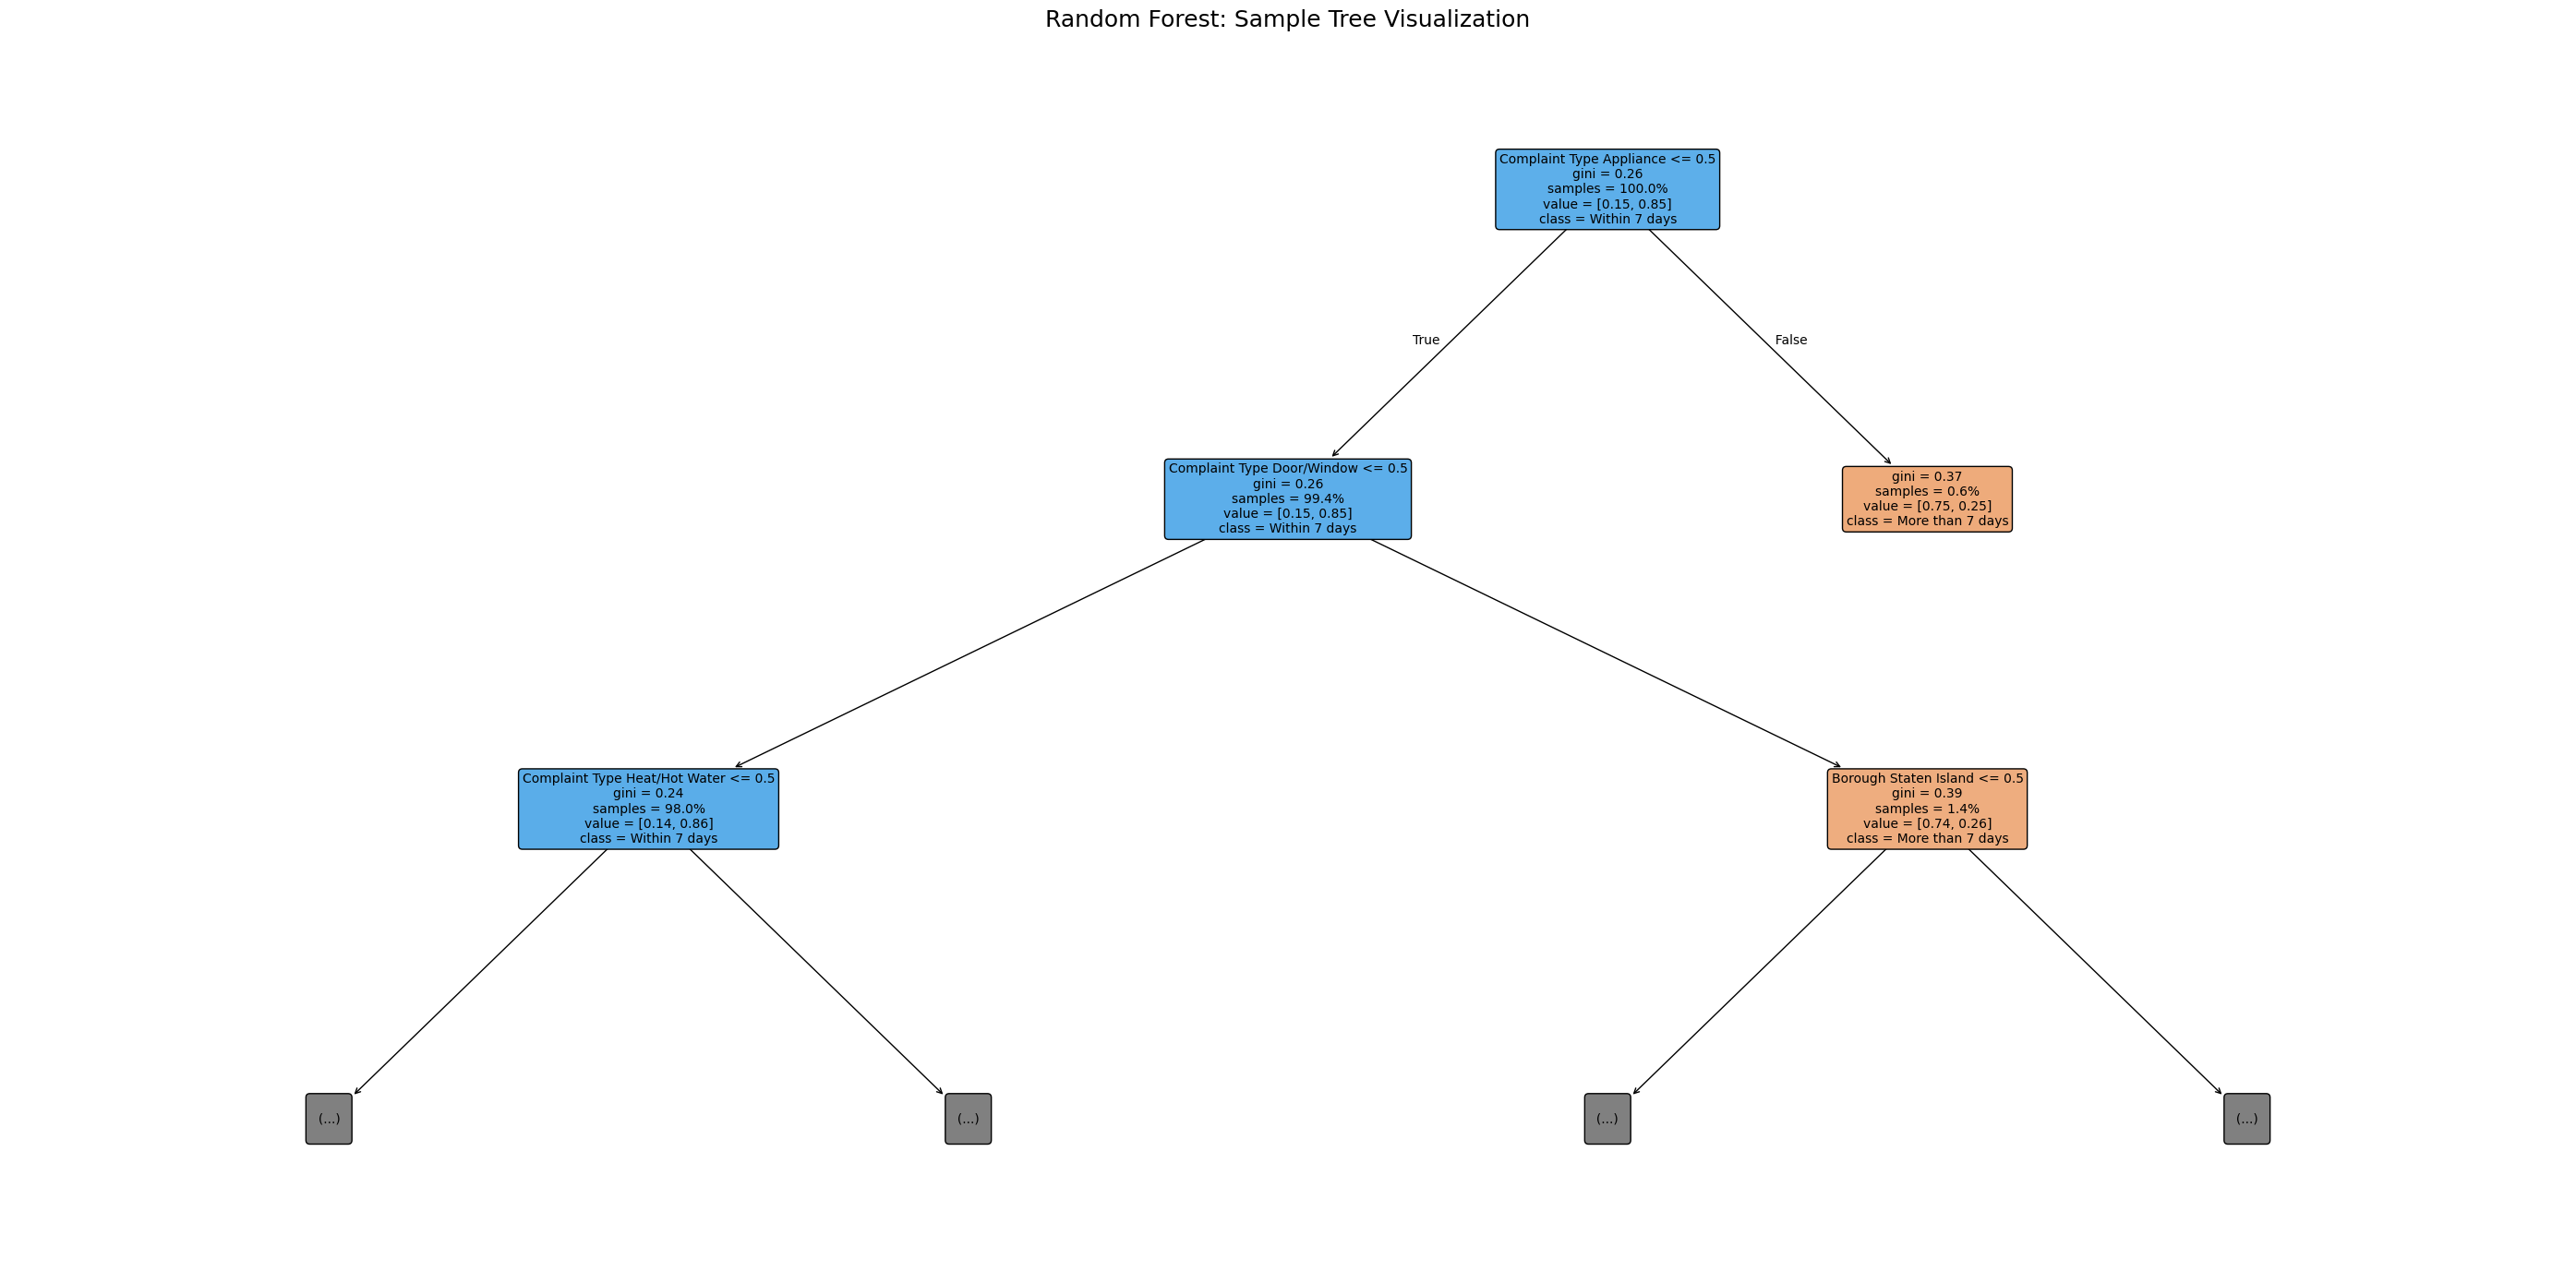

In [ ]:
# Visualize one tree only from the forest
one_tree = rf_pipeline.named_steps['model'].estimators_[0]

# Get feature names
feature_names = rf_pipeline.named_steps['preprocessor'].get_feature_names_out()

# Clean names
clean_feature_names = [
    f.replace('cat__', '').replace('num__', '').replace('_', ' ').title()
    for f in feature_names
]

plt.figure(figsize=(28, 14))

plot_tree(
    one_tree,
    feature_names=clean_feature_names,
    class_names=['More than 7 days', 'Within 7 days'],
    filled=True,
    rounded=True,
    proportion=True,
    precision=2,
    max_depth=2,
    fontsize=10
)

plt.title("Random Forest: Sample Tree Visualization", fontsize=18)
plt.tight_layout()
plt.show()

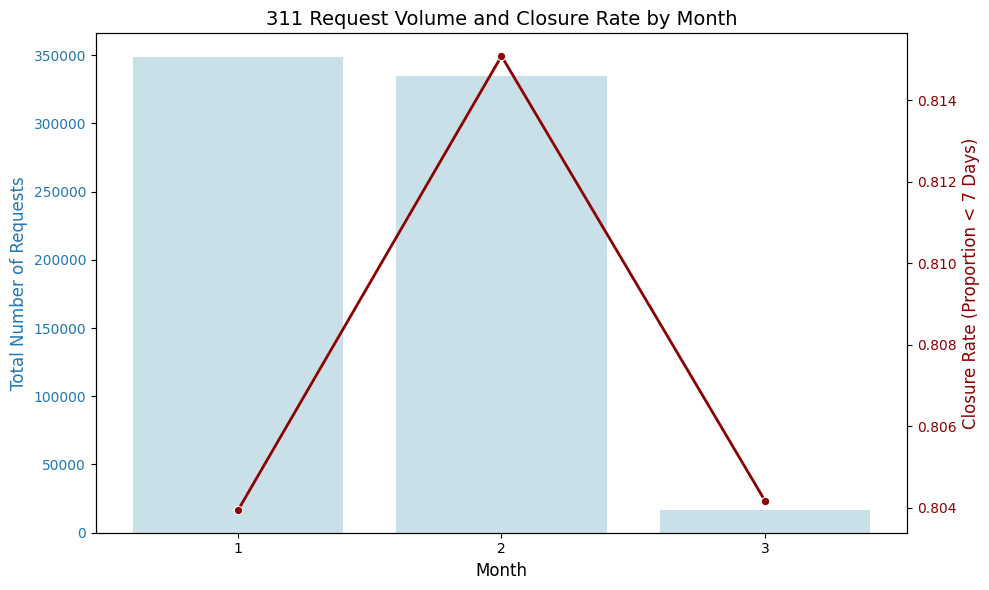

In [ ]:
# Group by month to get the total volume and the average closure rate
monthly_stats = df.groupby('month').agg(
    total_requests=('closed_within_7_days', 'count'),
    closure_rate=('closed_within_7_days', 'mean')
).reset_index()

# Create the figure and the first axis for the volume
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot Volume as a bar chart
sns.barplot(
    data=monthly_stats,
    x='month',
    y='total_requests',
    color='lightblue',
    ax=ax1,
    alpha=0.7
)
ax1.set_ylabel('Total Number of Requests', color='tab:blue', fontsize=12)
ax1.set_xlabel('Month', fontsize=12)
ax1.tick_params(axis='y', labelcolor='tab:blue')

# Create a second y-axis to plot the Closure Rate as a line chart
ax2 = ax1.twinx()
sns.lineplot(
    data=monthly_stats,
    x=monthly_stats.index, # using index to align with barplot's categorical x-axis
    y='closure_rate',
    color='darkred',
    marker='o',
    linewidth=2,
    ax=ax2
)
ax2.set_ylabel('Closure Rate (Proportion < 7 Days)', color='darkred', fontsize=12)
ax2.tick_params(axis='y', labelcolor='darkred')

plt.title('311 Request Volume and Closure Rate by Month', fontsize=14)
plt.tight_layout()
plt.show()

Cross-Validation + Final Metrics Tables - Lincon/Rojina

# Cross Validation

In [ ]:

scoring = ['accuracy', 'precision', 'recall', 'f1']

# Logisitical regression Cross Validation

In [ ]:
lr_cv_results

{'Model': ['Logistical Regression'],
 'CV Accuracy': [np.float64(0.9052716689627841)],
 'CV Precision': [np.float64(0.9467491359236722)],
 'CV Recall': [np.float64(0.9409691744859279)],
 'CV F1-score': [np.float64(0.9438501733104208)]}

## KNN Cross Validation

In [ ]:
knn_cv = cross_validate(
    knn_pipeline,
    X_knn,
    y_knn,
    cv=3,
    scoring=scoring,
    n_jobs=-1
)

knn_results = {
    'Model': 'KNN',
    'CV Accuracy': knn_cv['test_accuracy'].mean(),
    'CV Precision': knn_cv['test_precision'].mean(),
    'CV Recall': knn_cv['test_recall'].mean(),
    'CV F1-score': knn_cv['test_f1'].mean()
}

## Decision Tree Cross Validation

In [ ]:
dt_cv = cross_validate(
    tree_pipeline,
    X,
    y,
    cv=3,
    scoring=scoring,
    n_jobs=-1
)

dt_results = {
    'Model': 'Decision Tree',
    'CV Accuracy': dt_cv['test_accuracy'].mean(),
    'CV Precision': dt_cv['test_precision'].mean(),
    'CV Recall': dt_cv['test_recall'].mean(),
    'CV F1-score': dt_cv['test_f1'].mean()
}

## Random Forest Cross Validation

In [ ]:
rf_cv = cross_validate(
    rf_pipeline,
    X,
    y,
    cv=3,
    scoring=scoring,
    n_jobs=-1
)

rf_results = {
    'Model': 'Random Forest',
    'CV Accuracy': rf_cv['test_accuracy'].mean(),
    'CV Precision': rf_cv['test_precision'].mean(),
    'CV Recall': rf_cv['test_recall'].mean(),
    'CV F1-score': rf_cv['test_f1'].mean()
}

## Final Cross Validation Result Table

In [ ]:
cv_results_table = pd.DataFrame([
    knn_results,
    dt_results,
    rf_results,
    lr_cv_results
])

cv_results_table

,Model,CV Accuracy,CV Precision,CV Recall,CV F1-score
0,KNN,0.897167,0.934249,0.944885,0.939534
1,Decision Tree,0.892428,0.923545,0.951841,0.937383
2,Random Forest,0.874867,0.882671,0.982788,0.930028
3,[Logistical Regression],[0.9052716689627841],[0.9467491359236722],[0.9409691744859279],[0.9438501733104208]


## Logistic Regression Final Predictions for Unresolved Cases

The final table uses logistic regression because it had the strongest F1 score. The snapshot date is fixed at April 30, 2026. Any unresolved request already 7 or more days old is labeled 0 because it cannot still be closed within 7 days of creation.

In [ ]:
# Score unresolved cases with the logistic regression classifier
snapshot_date = pd.Timestamp('2026-04-30')

lr_unresolved_scored = unresolved_cases.copy()
lr_unresolved_scored['case_age_days'] = (
    snapshot_date - lr_unresolved_scored['created_date']
).dt.total_seconds() / 86400

X_unresolved_lr = lr_unresolved_scored[feature_cols].copy()
X_unresolved_lr = pd.get_dummies(X_unresolved_lr, drop_first=True, sparse=True)
X_unresolved_lr = X_unresolved_lr.reindex(columns=model.feature_names_in_, fill_value=0)

# Direct classifier output: 1 = predicted to close within 7 days, 0 = not predicted to close within 7 days
lr_unresolved_scored['lr_model_prediction'] = model.predict(X_unresolved_lr)

lr_unresolved_scored['lr_prob_close_within_7_days'] = model.predict_proba(X_unresolved_lr)[:, 1]

lr_unresolved_scored['lr_final_pred_close_within_7_days'] = np.where(
    lr_unresolved_scored['case_age_days'] >= 7,
    0,
    lr_unresolved_scored['lr_model_prediction']
)

print("Snapshot date used for unresolved-case scoring:", snapshot_date.date())
print("Unresolved cases:", len(lr_unresolved_scored))
print("Unresolved cases already open 7+ days:", int((lr_unresolved_scored['case_age_days'] >= 7).sum()))
print("Unresolved cases still inside 7-day window:", int((lr_unresolved_scored['case_age_days'] < 7).sum()))
print("Final prediction counts:")
print(lr_unresolved_scored['lr_final_pred_close_within_7_days'].value_counts().sort_index())


Snapshot date used for unresolved-case scoring: 2026-04-30
Unresolved cases: 34611
Unresolved cases already open 7+ days: 34611
Unresolved cases still inside 7-day window: 0
Final prediction counts:
lr_final_pred_close_within_7_days
0    34611
Name: count, dtype: int64


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(


In [ ]:
# Final logistic regression classification table for unresolved cases
lr_cols_to_show = [
    'unique_key',
    'status',
    'agency',
    'complaint_type',
    'borough',
    'created_date',
    'case_age_days',
    'lr_model_prediction',
    'lr_prob_close_within_7_days',
    'lr_final_pred_close_within_7_days'
]

display(
    lr_unresolved_scored[lr_cols_to_show]
    .sort_values('lr_prob_close_within_7_days', ascending=False)
    .head(20)
)


,unique_key,status,agency,complaint_type,borough,created_date,case_age_days,lr_model_prediction,lr_prob_close_within_7_days,lr_final_pred_close_within_7_days
634072,68110922,unspecified,nypd,noise - residential,bronx,2026-02-24,65.0,1,0.999984,0
286886,67638897,unspecified,nypd,noise - residential,bronx,2026-01-27,93.0,1,0.999978,0
685570,68169669,open,hpd,heat/hot water,staten island,2026-03-01,60.0,1,0.998654,0
360357,67806820,assigned,dohmh,indoor air quality,staten island,2026-02-01,88.0,1,0.998311,0
603495,68094346,open,hpd,heat/hot water,staten island,2026-02-23,66.0,1,0.998280,0
454456,67911749,open,hpd,heat/hot water,staten island,2026-02-09,80.0,1,0.998280,0
534222,68009835,open,hpd,heat/hot water,staten island,2026-02-16,73.0,1,0.998280,0
375348,67830536,open,hpd,heat/hot water,staten island,2026-02-02,87.0,1,0.998280,0
621398,68114072,open,hpd,heat/hot water,staten island,2026-02-24,65.0,1,0.998263,0
557430,68031352,open,hpd,heat/hot water,staten island,2026-02-18,71.0,1,0.998246,0


In [ ]:
predictions_filename = "nyc_311_unresolved_predictions.csv"

lr_cols_to_show = [
    'unique_key',
    'status',
    'agency',
    'complaint_type',
    'borough',
    'created_date',
    'case_age_days',
    'lr_model_prediction',
    'lr_prob_close_within_7_days',
    'lr_final_pred_close_within_7_days'
]

final_output_df = lr_unresolved_scored[lr_cols_to_show].sort_values(
    'lr_prob_close_within_7_days', ascending=False
)
final_output_df.to_csv(predictions_filename, index=False)
print(f"Dataset exported to: {predictions_filename}")

Dataset exported to: nyc_311_unresolved_predictions.csv


In [ ]:
final_output_df

,unique_key,status,agency,complaint_type,borough,created_date,case_age_days,lr_model_prediction,lr_prob_close_within_7_days,lr_final_pred_close_within_7_days
634072,68110922,unspecified,nypd,noise - residential,bronx,2026-02-24,65.0,1,0.999984,0
286886,67638897,unspecified,nypd,noise - residential,bronx,2026-01-27,93.0,1,0.999978,0
685570,68169669,open,hpd,heat/hot water,staten island,2026-03-01,60.0,1,0.998654,0
360357,67806820,assigned,dohmh,indoor air quality,staten island,2026-02-01,88.0,1,0.998311,0
603495,68094346,open,hpd,heat/hot water,staten island,2026-02-23,66.0,1,0.998280,0
...,...,...,...,...,...,...,...,...,...,...
695400,68178640,in progress,oos,cannabis retailer,brooklyn,2026-03-02,59.0,0,0.004224,0
693651,68186140,in progress,oos,cannabis retailer,brooklyn,2026-03-02,59.0,0,0.004224,0
687583,68173450,in progress,oos,cannabis retailer,brooklyn,2026-03-01,60.0,0,0.003986,0
638636,68132510,in progress,oos,cannabis retailer,brooklyn,2026-02-25,64.0,0,0.003060,0


Predicted Distribution of NYC 311 Request Closure Outcomes

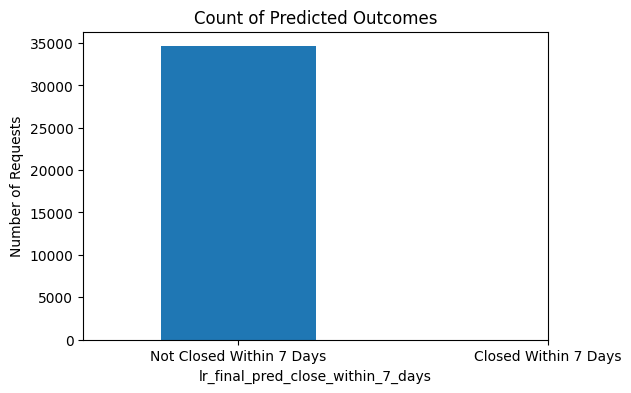

In [ ]:
prediction_counts = final_output_df['lr_final_pred_close_within_7_days'].value_counts()

plt.figure(figsize=(6,4))
prediction_counts.plot(kind='bar')

plt.xticks([0,1], ['Not Closed Within 7 Days', 'Closed Within 7 Days'], rotation=0)
plt.ylabel('Number of Requests')
plt.title('Count of Predicted Outcomes')

plt.show()

Figure shows the distribution of the model’s predicted outcomes for NYC 311 service requests. Most requests are predicted not to close within 7 days, while only a small portion are expected to be resolved within the target timeframe. These results are consistent with the earlier EDA findings, which identified delays and differences in closure rates across boroughs, agencies, and complaint types.

Distribution of Predicted Closure Probabilities

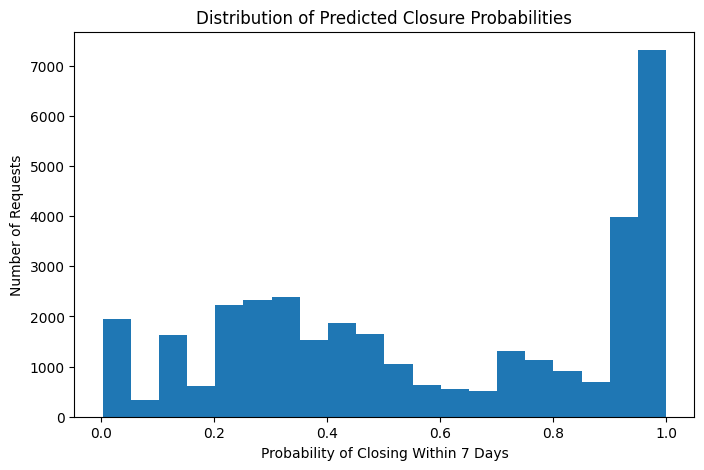

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(final_output_df['lr_prob_close_within_7_days'], bins=20)

plt.xlabel('Probability of Closing Within 7 Days')
plt.ylabel('Number of Requests')
plt.title('Distribution of Predicted Closure Probabilities')

plt.show()

Figure shows the distribution of predicted probabilities for NYC 311 service requests closing within 7 days. The probabilities are spread across a wide range of values, indicating that the model distinguishes between requests with low and high likelihoods of timely resolution. While many requests have lower predicted probabilities, a noticeable portion also shows high probabilities of closing within the target timeframe. This variation suggests that the model successfully captures differences in service request characteristics, such as borough, agency, complaint type, and case age, identified during the earlier exploratory data analysis.

Complaint Types Least Likely to Close Within 7 Days

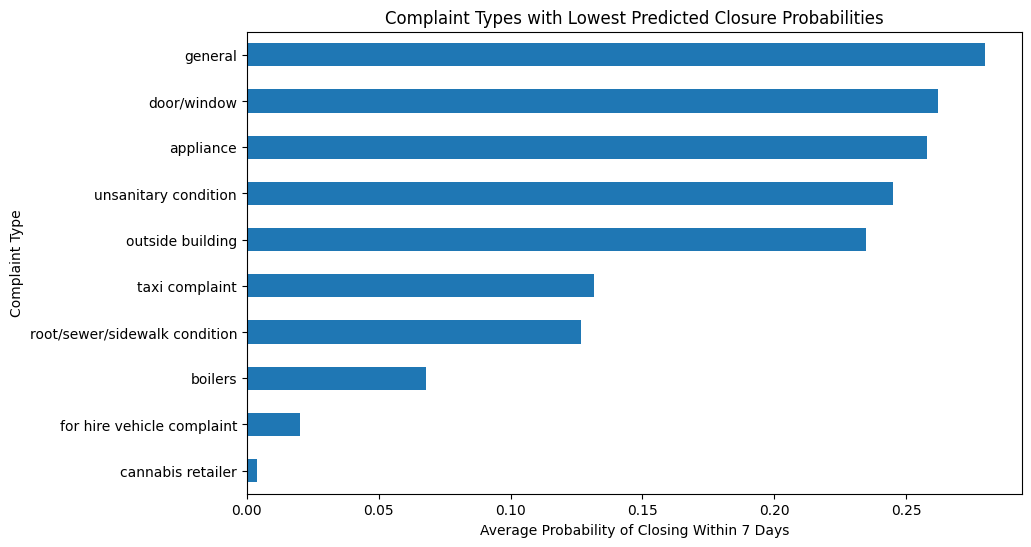

In [ ]:
complaint_pred = (
    final_output_df.groupby('complaint_type')['lr_prob_close_within_7_days']
    .mean()
    .sort_values()
    .head(10)
)

plt.figure(figsize=(10,6))

complaint_pred.plot(kind='barh')

plt.xlabel('Average Probability of Closing Within 7 Days')
plt.ylabel('Complaint Type')
plt.title('Complaint Types with Lowest Predicted Closure Probabilities')

plt.show()

Figure presents the complaint types with the lowest predicted probabilities of closing within 7 days. Complaints related to unsanitary conditions, boilers, and root or sidewalk conditions show particularly low predicted closure probabilities, suggesting that these requests are more likely to experience delays compared to other service categories. Unlike the previous figures, which focused on the overall distribution of predictions across the entire dataset, this figure provides a more detailed operational view by identifying the specific categories most associated with delayed resolution.

Insights:
1. Agency-Specific Performance Gaps: Feature importance plots and the Agency Workload vs. Efficiency scatter plot reveal that the responding Agency is a primary predictor of resolution time. Agencies like the NYPD and DSNY show very high closure rates, whereas others (like HPD, specifically for Heat/Hot Water issues) have significantly lower rates, indicating that resolution speed is often dictated by agency protocols and resources rather than the location of the complaint.
2. Complaint Type as a Critical Predictor: Certain complaint categories, such as 'Noise' and 'Illegal Parking', are consistently resolved faster than 'Unsanitary Condition' or 'Plumbing'. Your Decision Tree model highlighted 'Heat/Hot Water' as one of the most significant features for predicting longer resolution times, suggesting these infrastructure-heavy complaints are the primary bottleneck for city services.
3. High Class Imbalance & Efficiency: The 'Closed Within 7 Days' target variable shows that a vast majority of 311 requests are resolved within a week. This suggests high operational efficiency for common complaints, but it also creates a class imbalance that your models (like Logistic Regression and Random Forest) had to account for.

# Summary Statistics & Key Findings

The NYC 311 dataset showed substantial variation across complaint types, agencies, boroughs, and time periods. A small number of complaint categories accounted for a large share of total requests, suggesting that certain service issues create concentrated operational demand for NYC agencies.

Borough level analysis revealed meaningful differences in closure performance. The Bronx had one of the highest proportions of requests resolved within 7 days, while requests with unspecified borough information showed the lowest closure rates. These patterns suggest that geographic and operational factors may influence response efficiency.

Time based analysis also indicated that request activity and resolution outcomes vary across months, days, and hours, implying that service demand fluctuates systematically over time. Higher request volumes during peak periods may contribute to slower response times.

Overall, the exploratory analysis suggests that variables such as complaint type, borough, agency, and request timing contain meaningful predictive information for determining whether a request will close within 7 days. These findings support the use of classification models such as Logistic Regression and KNN for predictive analysis.

